# Dataset Exploration: output.csv
Using `exp_parameters` as the group identifier.

In [51]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
import operator as op
warnings.filterwarnings('ignore')

df = pd.read_csv('output_08-10-2026_09-03-11.csv',
                 parse_dates=["start_time", "end_time"],
                 date_format="%m-%d-%Y %H:%M:%S")

# if you need another csv then:
# df_temp = pd.read_csv('output_11-08-2026_18-44-17.csv')
# df = pd.concat([df, df_temp], ignore_index=True)

df['exp_parameters'] = df['exp_parameters'].astype(str).str.strip()

word_count = df['exp_parameters'].str.split().str.len()

df.loc[word_count == 1, 'exp_parameters'] = df['exp_parameters'] + ' default'

print(f'Shape: {df.shape}')
print(df['exp_parameters'].unique())

df['test_duration'] = df['end_time'] - df['start_time']


Shape: (5100, 51)
['VDSL mps' 'VDSL default' 'VDSL mnp' 'VDSL ptc' 'VDSL sdt' 'VDSL inc'
 'Fiber mps' 'Fiber default' 'Fiber mnp' 'Fiber ptc' 'Fiber sdt'
 'Fiber inc' 'Cable mps' 'Cable default' 'Cable mnp' 'Cable ptc'
 'Cable sdt' 'Cable inc']


In [52]:

rpm_cols = [c for c in df.columns if 'rpm' in c.lower()]

fieldnames = ['exp_parameters']
environment_parameters = ['dl_capacity', 'ul_capacity', 'dl_delay', 'ul_delay']

rpm_parameters = ['id', 'inc', 'inp', 'mad', 'mnp', 'mps', 'p', 'ptc', 'sdt', 'timeout', 'tmp']

dl_test_output = ['dl_stable_throughput', 'dl_stable_responsiveness', 'dl_throughput', 'dl_connections',
                   'dl_max_path_mtu', 'dl_max_send_mss', 'dl_max_recv_mss', 'dl_retransmissions',
                   'dl_reorder', 'dl_avg_rtt', 'dl_rpm_p', 'dl_rpm_trimmed']

ul_test_output = ['ul_stable_throughput', 'ul_stable_responsiveness', 'ul_throughput', 'ul_connections',
                   'ul_max_path_mtu', 'ul_max_send_mss', 'ul_max_recv_mss', 'ul_retransmissions',
                   'ul_reorder', 'ul_avg_rtt', 'ul_rpm_p', 'ul_rpm_trimmed']

final_test_output = ['final_rpm_p', 'final_rpm_trimmed']

relative_test_output = ['ub_base_rpm_p', 'ub_base_rpm_trimmed', 'base_rpm_p', 'base_rpm_trimmed',
                         'wc_effect_p', 'wc_effect_trimmed']
misc = ['iteration', 'start_time', 'end_time']

outputs = dl_test_output + ul_test_output + final_test_output + relative_test_output

not_relevant = ["mtu", "mss"]

outputs_for_plots = [
    item for item in outputs 
    if not any(sub in item for sub in not_relevant)
]


bool_cols = ['dl_stable_throughput', 'dl_stable_responsiveness',
             'ul_stable_throughput', 'ul_stable_responsiveness']

relevant_parameters = ['intervalDuration', 'connectionsPerInterval', 'connectionsInitial', 'movingAverageDistance', 'maxParallelConnections', 
                       'probesPerSecond', 'percentageOfResults', 'capacityOfProbes', 'stabilityCutoff', 'calculationTime']
for c in bool_cols:
    if c in df.columns and df[c].dtype == object:
        df[c] = df[c].map({'True': True, 'False': False})

environments = ['VDSL', 'Cable', 'Fiber']

# rename the parameters to something readable:
rename_map = {
    'id': 'intervalDuration',
    'inc': 'connectionsPerInterval', 
    'inp': 'connectionsInitial', 
    'mad': 'movingAverageDistance', 
    'mnp': 'maxParallelConnections', 
    'mps': 'probesPerSecond', 
    'p': 'percentageOfResults', 
    'ptc': 'capacityOfProbes', 
    'sdt': 'stabilityCutoff', 
    'timeout': 'calculationTime',
    'tmp': 'trimPercentage'
}

default_values = {
    'intervalDuration': 5,
    'connectionsPerInterval': 1,
    'connectionsInitial': 1,
    'movingAverageDistance': 4,
    'maxParallelConnections': 16,
    'probesPerSecond': 100,
    'percentageOfResults': 90,
    'capacityOfProbes': 0.05,
    'stabilityCutoff': 5,
    'calculationTime': 20,
    'trimPercentage': 5
}

df = df.rename(columns=rename_map)
for old_name, new_name in rename_map.items():
    # '\b' ensures we match the exact word, not parts of other words
    regex_pattern = rf'\b{old_name}\b'
    
    df['exp_parameters'] = df['exp_parameters'].str.replace(regex_pattern, new_name, regex=True)

parameter_ranges = {}

for param in relevant_parameters:
    parameter_ranges[param] = df[param].unique()

df.head()

,exp_parameters,dl_capacity,ul_capacity,dl_delay,ul_delay,intervalDuration,connectionsPerInterval,connectionsInitial,movingAverageDistance,maxParallelConnections,...,ub_base_rpm_p,ub_base_rpm_trimmed,base_rpm_p,base_rpm_trimmed,wc_effect_p,wc_effect_trimmed,iteration,start_time,end_time,test_duration
0,VDSL probesPerSecond,100,40,5,5,1,1,1,4,16,...,5419,5479,5417,5474,3,8,79,2026-10-08 14:53:04,2026-10-08 14:54:42,0 days 00:01:38
1,VDSL probesPerSecond,100,40,5,5,1,1,1,4,16,...,5415,5468,5418,5470,3,8,50,2026-10-08 14:04:05,2026-10-08 14:05:43,0 days 00:01:38
2,VDSL probesPerSecond,100,40,5,5,1,1,1,4,16,...,5424,5482,5427,5486,4,9,23,2026-10-08 13:18:30,2026-10-08 13:20:08,0 days 00:01:38
3,VDSL probesPerSecond,100,40,5,5,1,1,1,4,16,...,5417,5475,5423,5481,4,9,68,2026-10-08 14:34:30,2026-10-08 14:36:08,0 days 00:01:38
4,VDSL probesPerSecond,100,40,5,5,1,1,1,4,16,...,5409,5462,5406,5462,5,9,92,2026-10-08 15:15:02,2026-10-08 15:16:40,0 days 00:01:38


## 1. Invalid Test results

In [53]:
is_nan = df[rpm_cols].isna()
is_inf = df[rpm_cols].isin([np.inf, -np.inf])

invalid_rpm = is_nan | is_inf

unclean_df = df[invalid_rpm.any(axis=1)]

print(f"Count of invalid rows: {len(unclean_df)}")
print(f"Percentage of invalid rows: {((len(unclean_df))/(len(df))):.2%}")

Count of invalid rows: 0
Percentage of invalid rows: 0.00%


Interesting facts<br>
rpm_p calculates Inf, while rpm_trimmed calculates nan

In [54]:
dl_invalid_pairs = (unclean_df['dl_rpm_trimmed'].isna()) & (unclean_df['dl_rpm_p'].isin([np.inf, -np.inf]))
ul_invalid_pairs = (unclean_df['ul_rpm_trimmed'].isna()) & (unclean_df['ul_rpm_p'].isin([np.inf, -np.inf]))
dl_invalid_singles = (unclean_df['dl_rpm_trimmed'].isna()) ^ (unclean_df['dl_rpm_p'].isin([np.inf, -np.inf]))
ul_invalid_singles = (unclean_df['ul_rpm_trimmed'].isna()) ^ (unclean_df['ul_rpm_p'].isin([np.inf, -np.inf]))
final_invalid_rows = (unclean_df['final_rpm_trimmed'].isna()) | (unclean_df['final_rpm_p'].isin([np.inf, -np.inf]))

print(f"#Rows with invalid RPM pairs in download:  {dl_invalid_pairs.sum()}")
print(f"#Rows with invalid RPM pairs in upload:    {ul_invalid_pairs.sum()}")
print(f"#Rows with invalid RPM in final:           {final_invalid_rows.sum()}")
print(f"#Rows with invalid RPM in both directions: {(dl_invalid_pairs & ul_invalid_pairs).sum()}\n")
print(f"Rows where only either of RPM values is invalid in download: {dl_invalid_singles.sum()}")
print(f"Rows where only either of RPM values is invalid in upload:   {ul_invalid_singles.sum()}")

df_temp = unclean_df[(dl_invalid_pairs & ul_invalid_pairs)]

df_temp

#Rows with invalid RPM pairs in download:  0
#Rows with invalid RPM pairs in upload:    0
#Rows with invalid RPM in final:           0
#Rows with invalid RPM in both directions: 0

Rows where only either of RPM values is invalid in download: 0
Rows where only either of RPM values is invalid in upload:   0


,exp_parameters,dl_capacity,ul_capacity,dl_delay,ul_delay,intervalDuration,connectionsPerInterval,connectionsInitial,movingAverageDistance,maxParallelConnections,...,ub_base_rpm_p,ub_base_rpm_trimmed,base_rpm_p,base_rpm_trimmed,wc_effect_p,wc_effect_trimmed,iteration,start_time,end_time,test_duration


In [55]:
unclean_df.loc[unclean_df['dl_stable_responsiveness'] == True].exp_parameters.value_counts()

Series([], Name: count, dtype: int64)

In [56]:


invalid_counts = unclean_df['exp_parameters'].value_counts()
total_counts = df['exp_parameters'].value_counts()

summary_df = pd.DataFrame({
    'invalid_rows': invalid_counts,
    'total_rows': total_counts
}).fillna(0).astype(int).reset_index()

summary_df = summary_df[summary_df['invalid_rows'] > 0]

summary_df = summary_df.rename(columns={'index': 'exp_parameters'})
summary_df['percentage'] = (summary_df['invalid_rows'] / summary_df['total_rows']).map('{:.2%}'.format)
summary_df = summary_df.sort_values(by='percentage', ascending=False).reset_index(drop=True)


print(summary_df)

Empty DataFrame
Columns: [exp_parameters, invalid_rows, total_rows, percentage]
Index: []


## At which parameter did these errors occur?

In [57]:
# 1. Extract just the second word (the parameter or 'default') into a temporary column
unclean_df['clean_param'] = unclean_df['exp_parameters'].str.split().str[1]
df['clean_param'] = df['exp_parameters'].str.split().str[1]

# 2. Combine the value counts into your summary DataFrame
summary_df = pd.DataFrame({
    'invalid_rows': unclean_df['clean_param'].value_counts(),
    'total_rows': df['clean_param'].value_counts()
}).fillna(0).astype(int)

unclean_df = unclean_df.drop(columns=['clean_param'])
df = df.drop(columns=['clean_param'])

# 3. Filter out rows with 0 invalid records and reset the index
summary_df = summary_df[summary_df['invalid_rows'] > 0].reset_index()
summary_df = summary_df.rename(columns={'index': 'exp_parameter'})

# 4. Calculate the failure percentage and sort by the highest number of invalid rows
summary_df = summary_df.sort_values(by='invalid_rows', ascending=False).reset_index(drop=True)
summary_df['percentage'] = (summary_df['invalid_rows'] / summary_df['total_rows']).map('{:.2%}'.format)

# Render the final table
print(summary_df)

Empty DataFrame
Columns: [clean_param, invalid_rows, total_rows, percentage]
Index: []


## heatmap

build the df:

In [58]:
foreign_rpm_cols = ['dl_rpm_p', 'dl_rpm_trimmed', 'ul_rpm_p', 'ul_rpm_trimmed']

heatmap_df = pd.DataFrame(columns=['exp_parameters', 'param_setting'])

for exp in df['exp_parameters'].dropna().astype(str).unique():
    parts = exp.split()
    if len(parts) < 2:
        continue

    parameter = parts[1]

    # ignore real "default" experiments as their own row
    if parameter == 'default':
        continue

    param_values = list(parameter_ranges.get(parameter, []))
    default_value = default_values.get(parameter)

    settings = []
    if default_value is not None:
        settings.append(default_value)
    settings.extend(v for v in param_values if v != default_value)
    settings = list(dict.fromkeys(settings))

    for value in settings:
        heatmap_df = pd.concat(
            [heatmap_df, pd.DataFrame([{'exp_parameters': exp, 'param_setting': value}])],
            ignore_index=True
        )

for rpm in foreign_rpm_cols:
    heatmap_df[f'invalid_{rpm}'] = 0

for exp in heatmap_df['exp_parameters'].dropna().astype(str).unique():
    exp_df = unclean_df[unclean_df['exp_parameters'] == exp]
    if exp_df.empty:
        continue

    parameter = exp.split()[1]
    param_values = list(parameter_ranges.get(parameter, []))
    default_value = default_values.get(parameter)

    settings = []
    if default_value is not None:
        settings.append(default_value)
    settings.extend(v for v in param_values if v != default_value)
    settings = list(dict.fromkeys(settings))

    for value in settings:
        for rpm in foreign_rpm_cols:
            invalid_count = (
                (exp_df[parameter] == value) &
                (exp_df[rpm].isna() | exp_df[rpm].isin([np.inf, -np.inf]))
            ).sum()

            loc_mask = (heatmap_df['exp_parameters'] == exp) & (heatmap_df['param_setting'] == value)
            heatmap_df.loc[loc_mask, f'invalid_{rpm}'] = invalid_count

In [59]:
heatmap_df.head()

,exp_parameters,param_setting,invalid_dl_rpm_p,invalid_dl_rpm_trimmed,invalid_ul_rpm_p,invalid_ul_rpm_trimmed
0,VDSL probesPerSecond,100,0,0,0,0
1,VDSL probesPerSecond,60,0,0,0,0
2,VDSL probesPerSecond,80,0,0,0,0
3,VDSL probesPerSecond,140,0,0,0,0
4,VDSL probesPerSecond,40,0,0,0,0


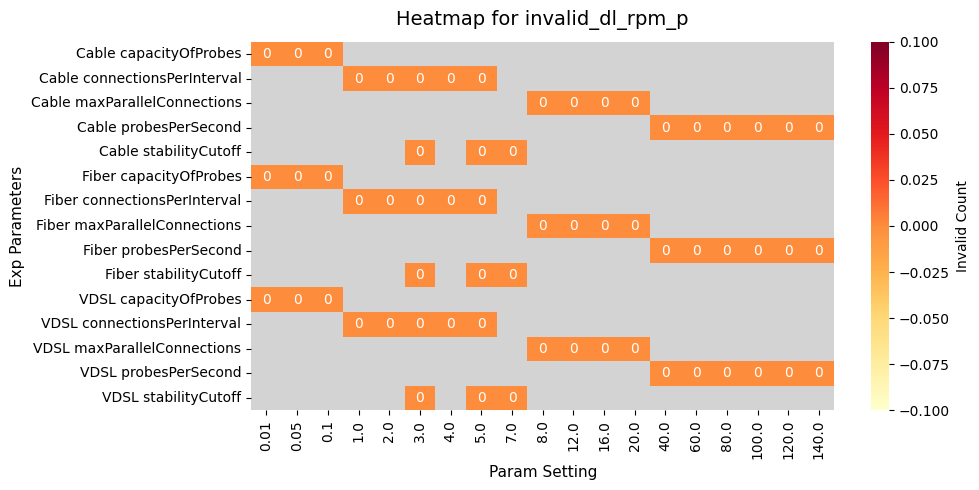

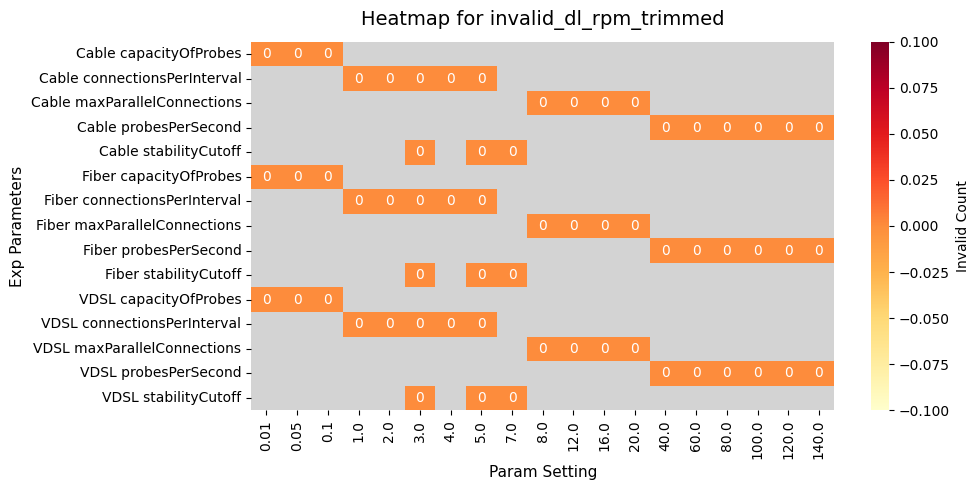

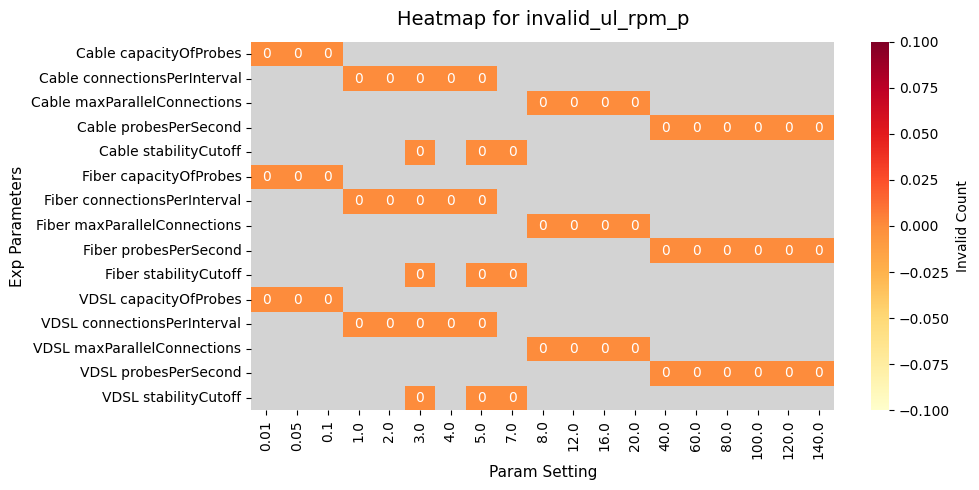

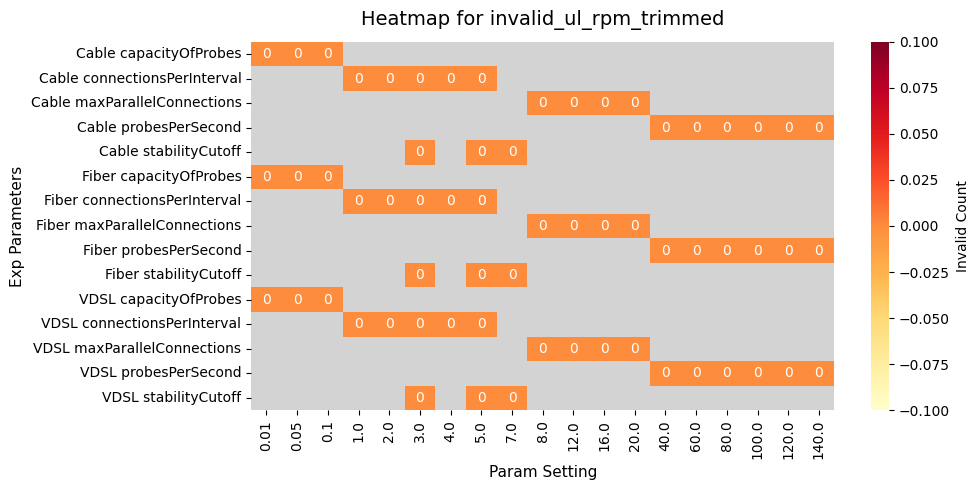

In [60]:
invalid_rpm_cols = [col for col in heatmap_df.columns if col.startswith('invalid')]

for col in invalid_rpm_cols:
    pivot_df = heatmap_df.pivot(
        index='exp_parameters', columns='param_setting', values=col
    )

    plt.figure(figsize=(10, 5))

    ax = plt.gca()
    ax.set_facecolor('#d3d3d3')

    sns.heatmap(
        pivot_df,
        annot=True,
        fmt='g',
        cmap='YlOrRd',
        mask=pivot_df.isna(),
        cbar_kws={'label': 'Invalid Count'},
        ax=ax,
    )

    plt.title(f'Heatmap for {col}', fontsize=14, pad=12)
    plt.xlabel('Param Setting', fontsize=11)
    plt.ylabel('Exp Parameters', fontsize=11)
    plt.tight_layout()

    plt.show()

- Default test is the most stable (when it comes to invalid data)
- The 'p' parameter seems to be most affected, BUT the range is higher so there will be more 'p' data than other parameters

## In which network did these errors occur?

In [61]:
# 1. Extract just the second word (the parameter or 'default') into a temporary column
unclean_df['clean_net'] = unclean_df['exp_parameters'].str.split().str[0]
df['clean_net'] = df['exp_parameters'].str.split().str[0]

# 2. Combine the value counts into your summary DataFrame
summary_df = pd.DataFrame({
    'invalid_rows': unclean_df['clean_net'].value_counts(),
    'total_rows': df['clean_net'].value_counts()
}).fillna(0).astype(int)

unclean_df = unclean_df.drop(columns=['clean_net'])
df = df.drop(columns=['clean_net'])

# 3. Filter out rows with 0 invalid records and reset the index
summary_df = summary_df[summary_df['invalid_rows'] > 0].reset_index()
summary_df = summary_df.rename(columns={'index': 'exp_parameter'})

# 4. Calculate the failure percentage and sort by the highest number of invalid rows
summary_df = summary_df.sort_values(by='invalid_rows', ascending=False).reset_index(drop=True)
summary_df['percentage'] = (summary_df['invalid_rows'] / summary_df['total_rows']).map('{:.2%}'.format)

# Render the final table
print(summary_df)

Empty DataFrame
Columns: [clean_net, invalid_rows, total_rows, percentage]
Index: []


## 2. One dimensional test (Environment)

## Environments

In [62]:

is_nan = df[rpm_cols].isna()
is_inf = df[rpm_cols].isin([np.inf, -np.inf])
invalid_rpm = is_nan | is_inf

df_clean = df[~invalid_rpm.any(axis=1)].copy()

df_clean = df_clean.reset_index(drop=True)

print(f"Original DataFrame rows: {len(df)}")
print(f"Cleaned DataFrame rows:  {len(df_clean)}")
print(f"Successfully removed:    {len(df) - len(df_clean)} invalid rows.")
print(df_clean['exp_parameters'].unique())

Original DataFrame rows: 5100
Cleaned DataFrame rows:  5100
Successfully removed:    0 invalid rows.
['VDSL probesPerSecond' 'VDSL default' 'VDSL maxParallelConnections'
 'VDSL capacityOfProbes' 'VDSL stabilityCutoff'
 'VDSL connectionsPerInterval' 'Fiber probesPerSecond' 'Fiber default'
 'Fiber maxParallelConnections' 'Fiber capacityOfProbes'
 'Fiber stabilityCutoff' 'Fiber connectionsPerInterval'
 'Cable probesPerSecond' 'Cable default' 'Cable maxParallelConnections'
 'Cable capacityOfProbes' 'Cable stabilityCutoff'
 'Cable connectionsPerInterval']


## Stability

In [63]:
default_experiments = [exp for exp in df_clean['exp_parameters'].unique() if str(exp).split()[1] == 'default']
df_default = df_clean[df_clean['exp_parameters'].isin(default_experiments)].copy()

# 2. Iterate through each single-substring experiment
for exp in default_experiments:
    # Isolate rows for this specific baseline experiment
    df_exp = df_default[df_default['exp_parameters'] == exp]
    
    # Automatically identify all boolean columns in this subset
    bool_cols = df_exp.select_dtypes(include=['bool']).columns.tolist()
    
    if not bool_cols:
        print(f"No boolean parameters found for experiment: '{exp}'\n")
        continue
        
    print(f"Analysis for Baseline Experiment: '{exp}'")
    print("-" * 65)
    print(f"{'Boolean Parameter':<25} {'Total Rows':<12} {'True Count':<12} {'Percentage'}")
    print("-" * 65)
    
    # 3. Calculate metrics for each boolean column
    for col in bool_cols:
        total_rows = len(df_exp)
        true_count = df_exp[col].sum()  # Summing a boolean column counts the True values
        
        # Avoid division by zero just in case the filtered dataframe is empty
        percentage = (true_count / total_rows * 100) if total_rows > 0 else 0.0
        
        print(f"{col:<25} {total_rows:<12} {true_count:<12} {percentage:.2f}%")
    
    print("\n" + "="*65 + "\n")

Analysis for Baseline Experiment: 'VDSL default'
-----------------------------------------------------------------
Boolean Parameter         Total Rows   True Count   Percentage
-----------------------------------------------------------------
dl_stable_throughput      100          0            0.00%
dl_stable_responsiveness  100          0            0.00%
ul_stable_throughput      100          0            0.00%
ul_stable_responsiveness  100          0            0.00%


Analysis for Baseline Experiment: 'Fiber default'
-----------------------------------------------------------------
Boolean Parameter         Total Rows   True Count   Percentage
-----------------------------------------------------------------
dl_stable_throughput      100          0            0.00%
dl_stable_responsiveness  100          0            0.00%
ul_stable_throughput      100          0            0.00%
ul_stable_responsiveness  100          0            0.00%


Analysis for Baseline Experiment: 'Cable de

## Numeric outputs

Found 3 single-substring baseline experiments: ['VDSL default', 'Fiber default', 'Cable default']
 REPORT & VISUALIZATION FOR BASELINE METRIC: DL_THROUGHPUT
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      231.97     231.96     0.04       0.00        
Fiber default    100      559.75     559.73     0.39       0.15        
VDSL default     100      91.63      91.63      0.02       0.00        
---------------------------------------------------------------------------

Visual Distribution:


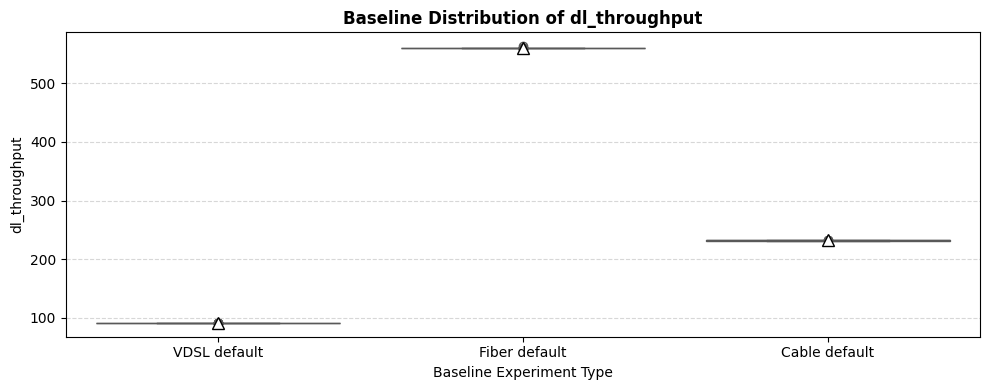


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: DL_CONNECTIONS
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      6.01       6.00       0.10       0.01        
Fiber default    100      6.04       6.00       0.20       0.04        
VDSL default     100      6.00       6.00       0.00       0.00        
---------------------------------------------------------------------------

Visual Distribution:


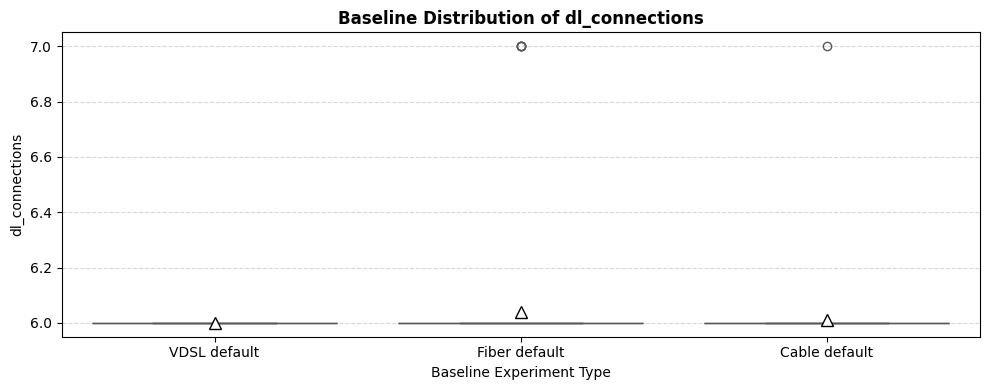


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: DL_RETRANSMISSIONS
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      0.00       0.00       0.00       0.00        
Fiber default    100      0.11       0.00       0.37       0.14        
VDSL default     100      0.00       0.00       0.00       0.00        
---------------------------------------------------------------------------

Visual Distribution:


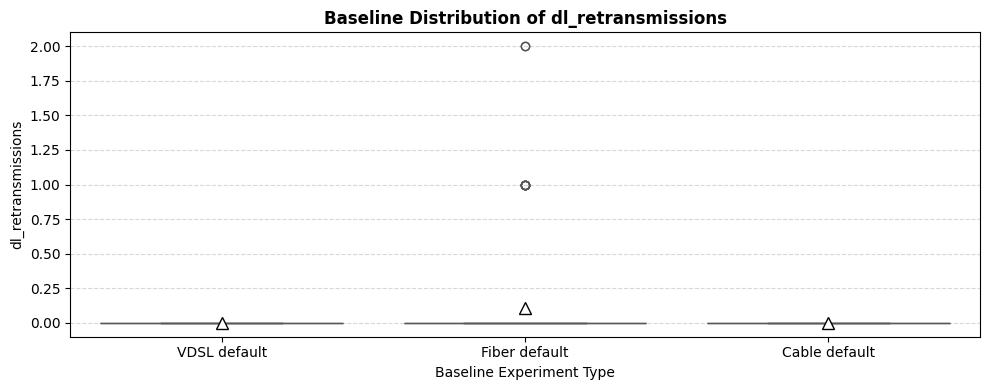


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: DL_REORDER
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      21.00      21.00      0.00       0.00        
Fiber default    100      21.00      21.00      0.00       0.00        
VDSL default     100      21.00      21.00      0.00       0.00        
---------------------------------------------------------------------------

Visual Distribution:


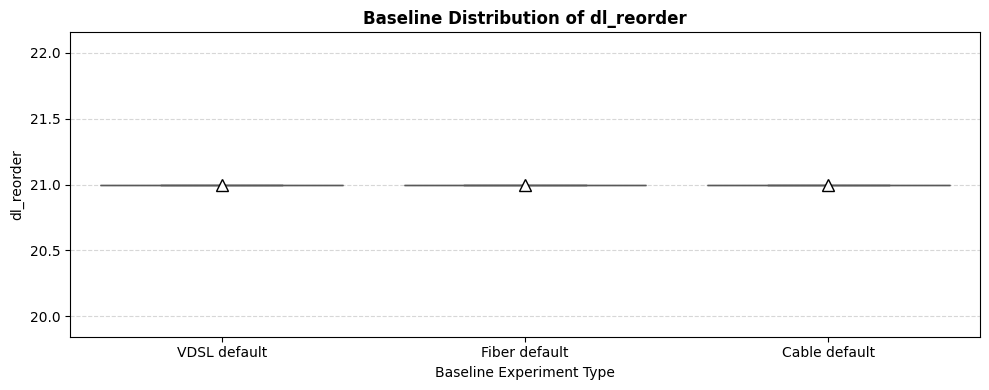


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: DL_AVG_RTT
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      21847.88   21781.79   212.77     45271.52    
Fiber default    100      10366.29   10343.50   208.29     43384.54    
VDSL default     100      13278.47   13276.71   177.22     31405.83    
---------------------------------------------------------------------------

Visual Distribution:


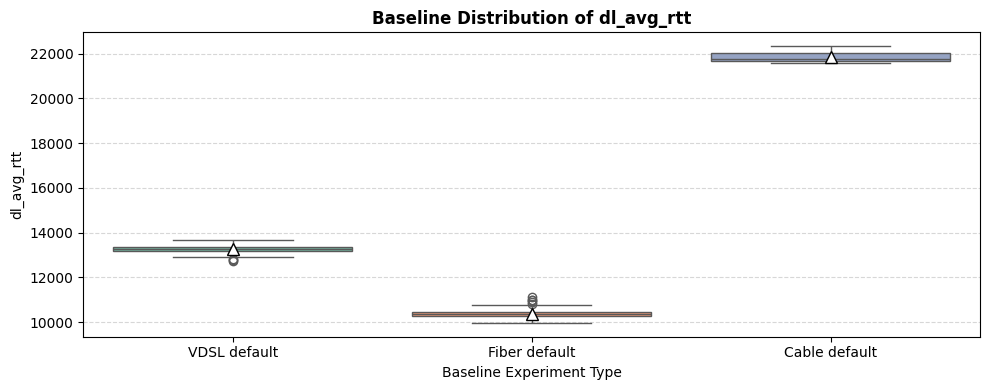


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: DL_RPM_P
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      609.06     627.00     54.43      2962.22     
Fiber default    100      961.09     946.00     114.89     13199.11    
VDSL default     100      606.51     607.50     25.16      633.08      
---------------------------------------------------------------------------

Visual Distribution:


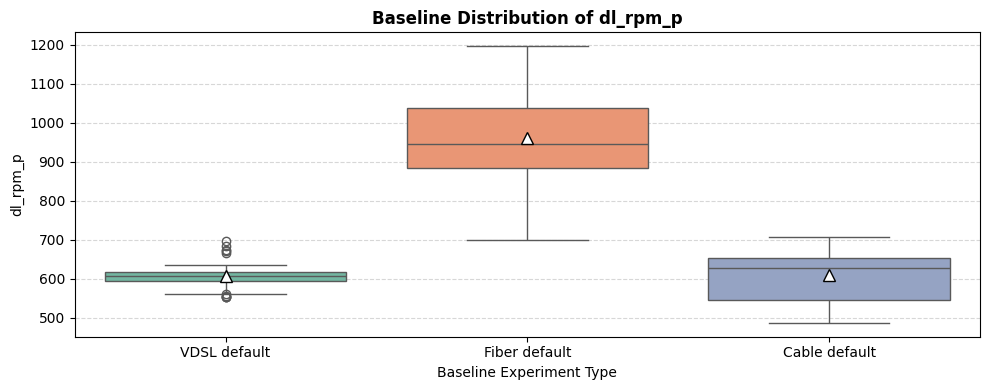


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: DL_RPM_TRIMMED
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      749.86     773.50     59.82      3578.49     
Fiber default    100      1255.23    1236.50    109.72     12039.19    
VDSL default     100      734.60     733.00     25.61      656.06      
---------------------------------------------------------------------------

Visual Distribution:


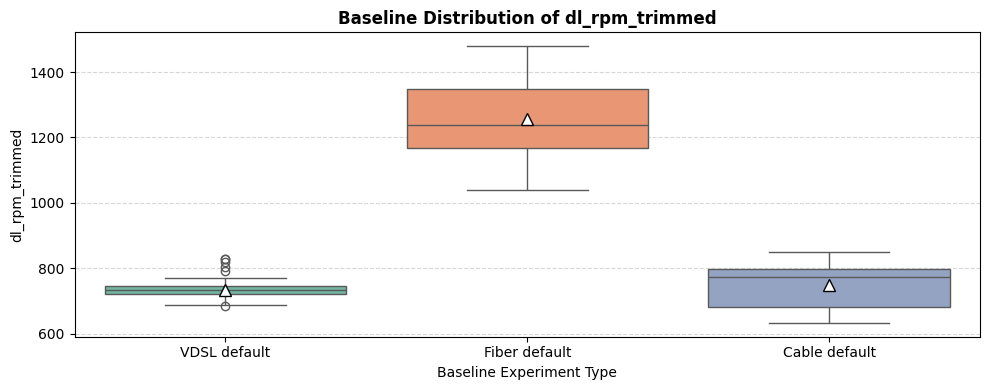


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: UL_THROUGHPUT
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      45.99      45.97      0.20       0.04        
Fiber default    100      280.90     280.86     0.14       0.02        
VDSL default     100      36.58      36.58      0.13       0.02        
---------------------------------------------------------------------------

Visual Distribution:


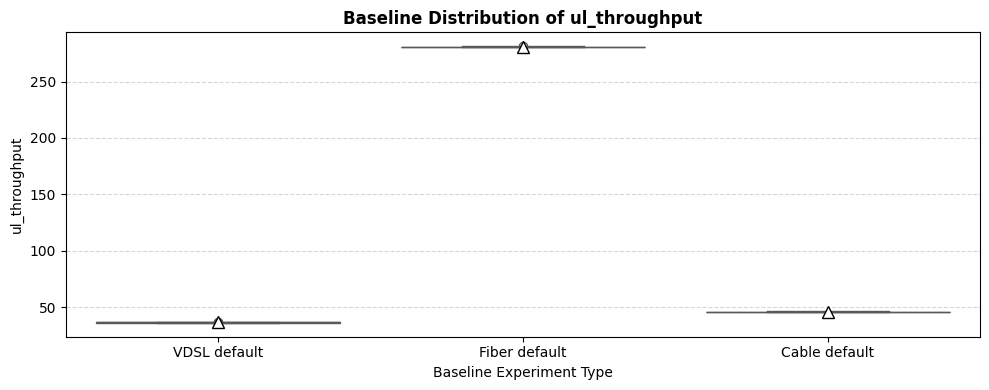


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: UL_CONNECTIONS
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      6.00       6.00       0.00       0.00        
Fiber default    100      6.00       6.00       0.00       0.00        
VDSL default     100      6.00       6.00       0.00       0.00        
---------------------------------------------------------------------------

Visual Distribution:


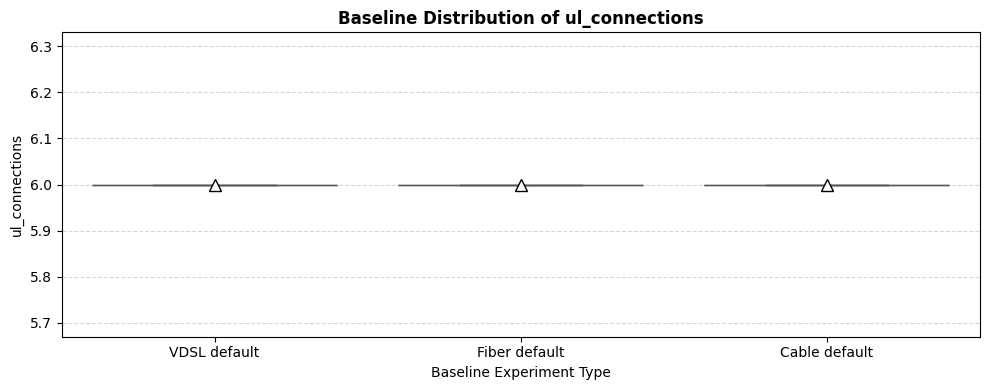


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: UL_RETRANSMISSIONS
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      0.04       0.00       0.20       0.04        
Fiber default    100      0.23       0.00       0.45       0.20        
VDSL default     100      0.01       0.00       0.10       0.01        
---------------------------------------------------------------------------

Visual Distribution:


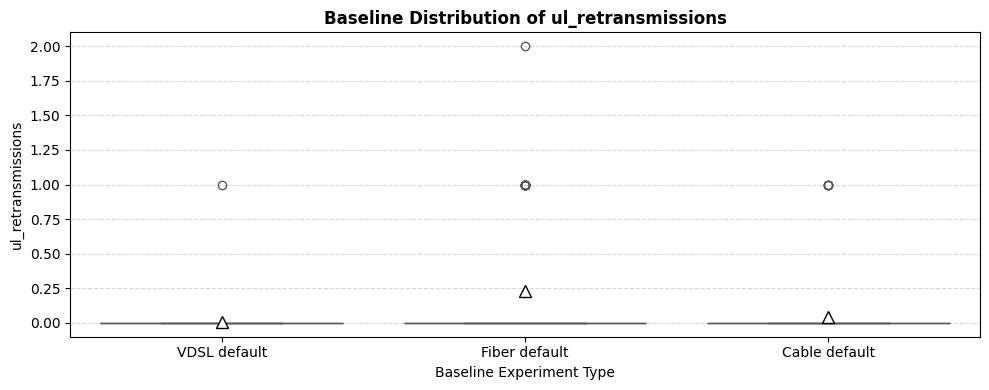


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: UL_REORDER
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      21.29      21.00      1.44       2.09        
Fiber default    100      46.76      34.00      29.85      890.97      
VDSL default     100      21.04      21.00      0.40       0.16        
---------------------------------------------------------------------------

Visual Distribution:


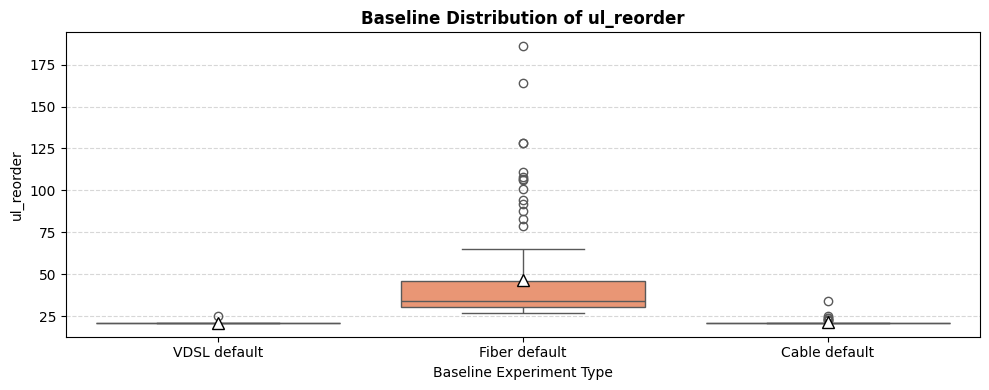


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: UL_AVG_RTT
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      25645.81   25586.93   289.37     83737.39    
Fiber default    100      10767.08   10704.29   266.10     70811.40    
VDSL default     100      16947.23   16908.21   387.76     150358.49   
---------------------------------------------------------------------------

Visual Distribution:


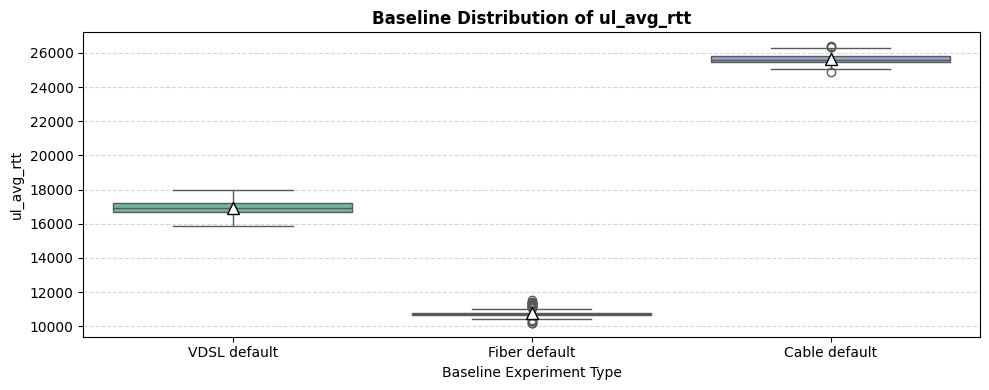


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: UL_RPM_P
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      27.89      28.00      3.67       13.47       
Fiber default    100      875.95     891.00     118.24     13980.80    
VDSL default     100      28.98      29.00      3.54       12.52       
---------------------------------------------------------------------------

Visual Distribution:


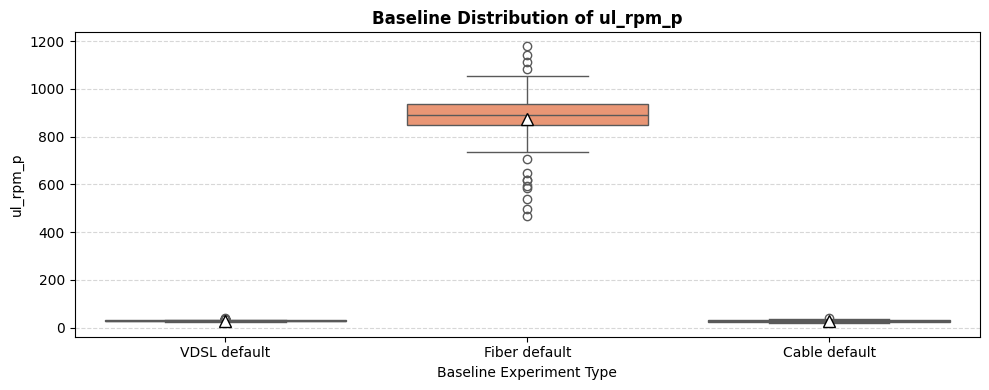


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: UL_RPM_TRIMMED
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      65.14      65.00      7.15       51.15       
Fiber default    100      1269.44    1287.00    108.12     11690.01    
VDSL default     100      71.01      71.00      8.02       64.29       
---------------------------------------------------------------------------

Visual Distribution:


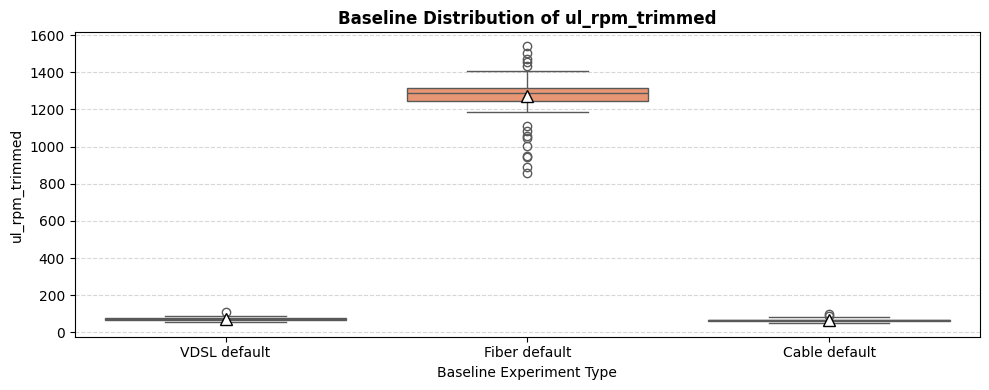


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: FINAL_RPM_P
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      41.72      41.00      4.67       21.82       
Fiber default    100      876.28     884.50     96.43      9298.61     
VDSL default     100      44.27      44.00      5.48       30.06       
---------------------------------------------------------------------------

Visual Distribution:


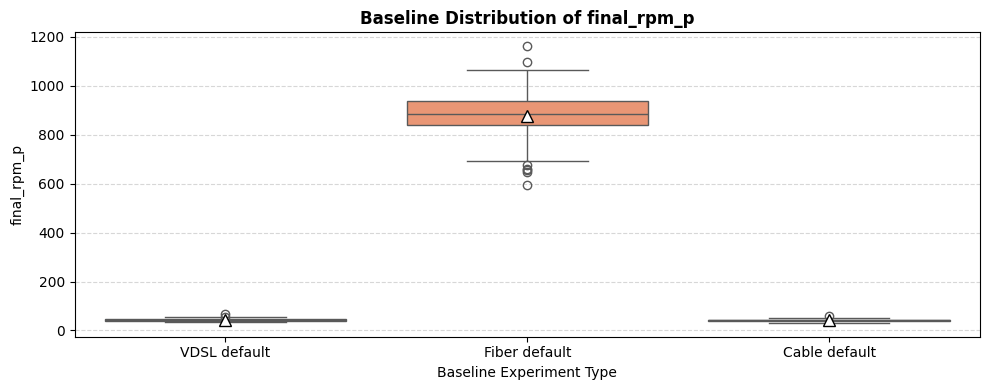


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: FINAL_RPM_TRIMMED
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      168.37     166.50     15.74      247.85      
Fiber default    100      1219.24    1211.50    78.66      6188.02     
VDSL default     100      179.18     177.00     15.28      233.56      
---------------------------------------------------------------------------

Visual Distribution:


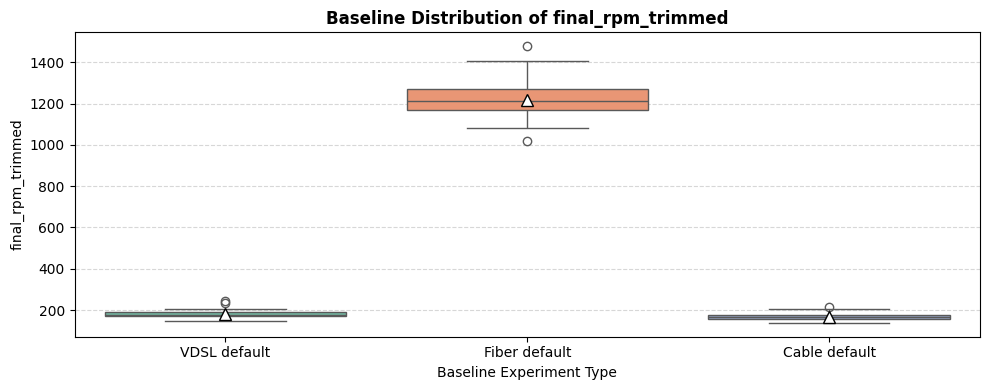


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: UB_BASE_RPM_P
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      2840.67    2841.00    6.05       36.61       
Fiber default    100      6628.11    6627.00    9.61       92.44       
VDSL default     100      5453.77    5453.00    4.76       22.62       
---------------------------------------------------------------------------

Visual Distribution:


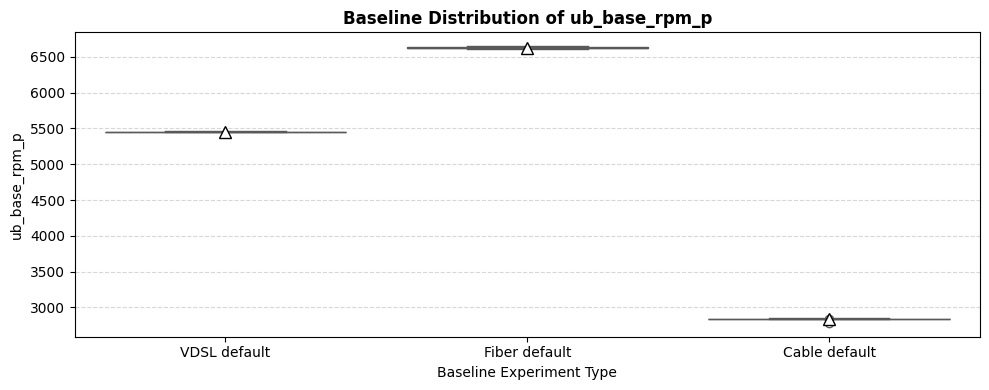


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: UB_BASE_RPM_TRIMMED
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      2857.05    2857.00    2.75       7.58        
Fiber default    100      6719.14    6718.00    9.30       86.55       
VDSL default     100      5481.67    5481.00    5.12       26.20       
---------------------------------------------------------------------------

Visual Distribution:


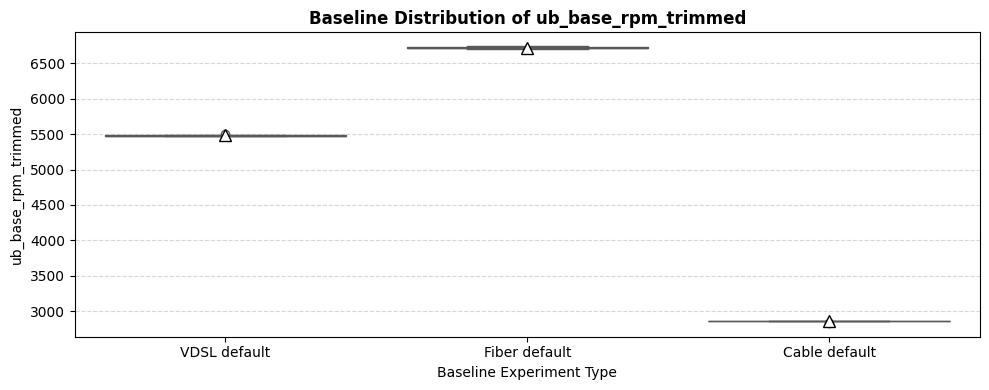


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: BASE_RPM_P
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      2839.44    2840.00    5.59       31.30       
Fiber default    100      6623.94    6623.50    10.73      115.07      
VDSL default     100      5452.17    5451.00    4.74       22.47       
---------------------------------------------------------------------------

Visual Distribution:


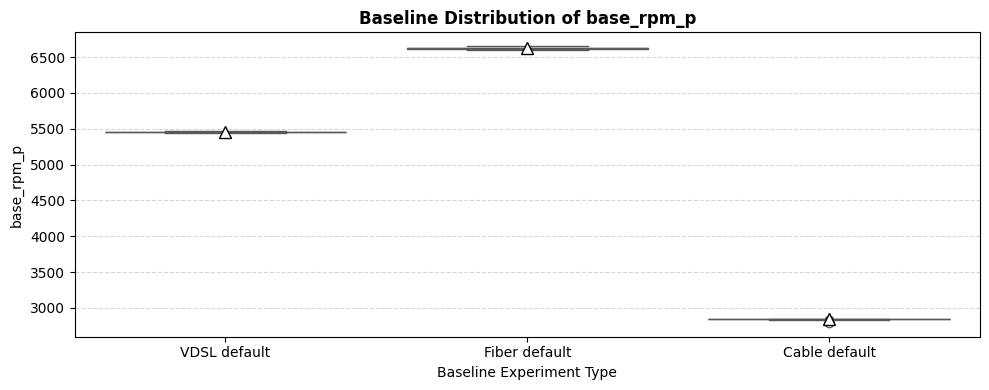


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: BASE_RPM_TRIMMED
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      2856.61    2857.00    1.87       3.51        
Fiber default    100      6717.98    6718.00    9.43       88.87       
VDSL default     100      5481.45    5482.00    4.92       24.17       
---------------------------------------------------------------------------

Visual Distribution:


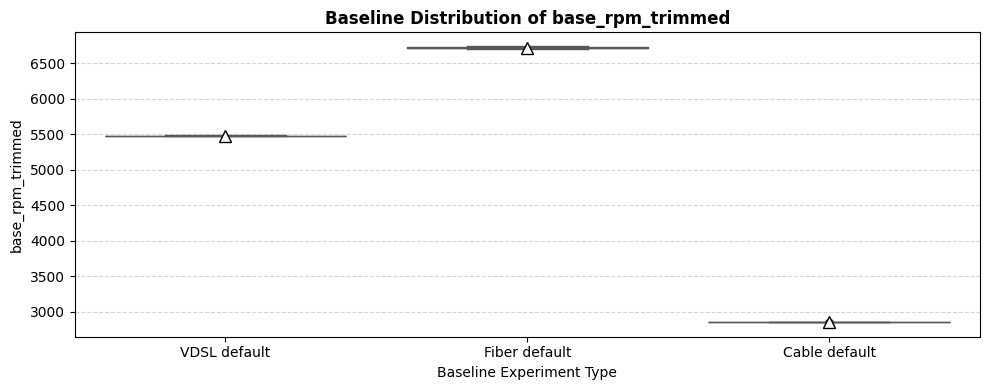


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: WC_EFFECT_P
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      1.36       1.00       0.48       0.23        
Fiber default    100      13.21      13.00      1.52       2.31        
VDSL default     100      1.00       1.00       0.00       0.00        
---------------------------------------------------------------------------

Visual Distribution:


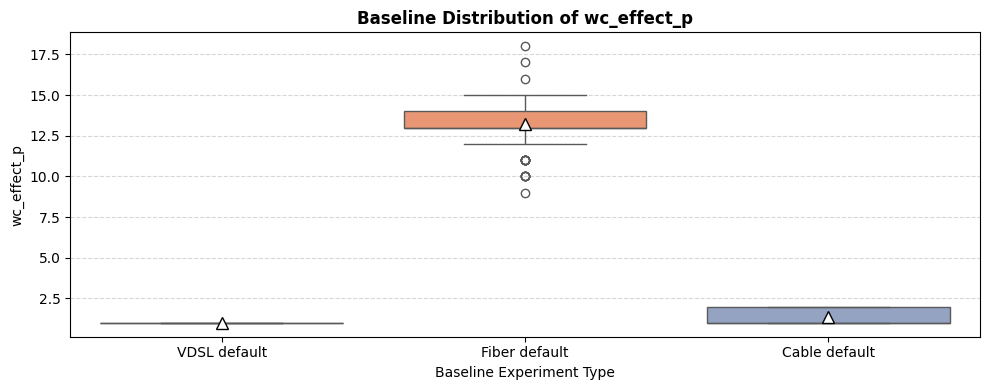


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

 REPORT & VISUALIZATION FOR BASELINE METRIC: WC_EFFECT_TRIMMED
Experiment Type  Count    Mean       Median     Std Dev    Variance    
---------------------------------------------------------------------------
Cable default    100      5.88       6.00       0.67       0.45        
Fiber default    100      18.16      18.00      1.20       1.43        
VDSL default     100      3.18       3.00       0.39       0.15        
---------------------------------------------------------------------------

Visual Distribution:


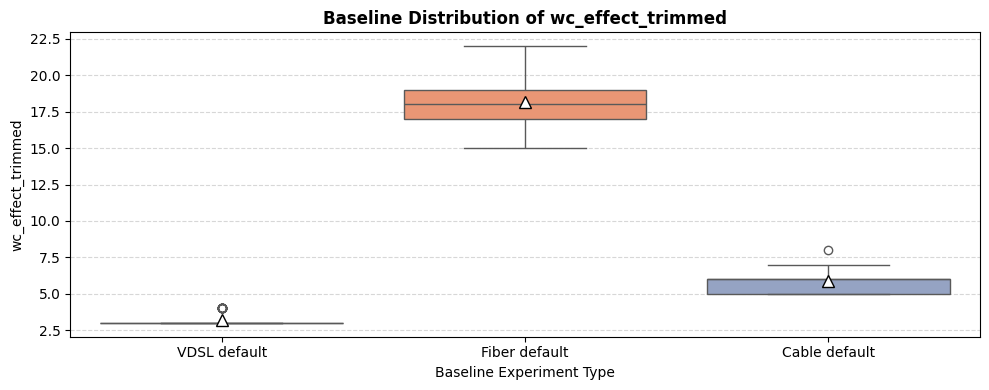


xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx



In [64]:
print(f"Found {len(default_experiments)} single-substring baseline experiments: {default_experiments}")

# --- 3. MAIN BLOCK UNIFIED LOOP ---
for col in outputs_for_plots:
    # Skip if the metric is completely missing from the dataframe
    if col not in df_default.columns:
        continue
    if col in bool_cols:
        continue
        
    # Force numeric parsing to clear out any leftover object data types
    df_default[col] = pd.to_numeric(df_default[col], errors='coerce')
    
    # --- A: PRINT STATISTICAL SUMMARY TABLE ---
    print("=" * 75)
    print(f" REPORT & VISUALIZATION FOR BASELINE METRIC: {col.upper()}")
    print("=" * 75)
    print(f"{'Experiment Type':<16} {'Count':<8} {'Mean':<10} {'Median':<10} {'Std Dev':<10} {'Variance':<12}")
    print("-" * 75)
    
    # Calculate essential metrics across the single-word experiments group
    stats = df_default.groupby('exp_parameters')[col].agg([
        'count', 'mean', 'median', 'std', 'var'
    ]).reset_index()
    
    stats.columns = ['exp_parameters', 'count', 'mean', 'median', 'std', 'var']
    
    for _, row in stats.iterrows():
        print(f"{str(row['exp_parameters']):<16} "
              f"{int(row['count']):<8} "
              f"{row['mean']:<10.2f} "
              f"{row['median']:<10.2f} "
              f"{row['std']:<10.2f} "
              f"{row['var']:<12.2f}")
    print("-" * 75)
    print("\nVisual Distribution:")

    # --- B: RENDER THE CORRESPONDING BOX PLOT ---
    plt.figure(figsize=(10, 4))
    
    sns.boxplot(
        data=df_default, 
        x='exp_parameters', 
        y=col, 
        palette='Set2',
        showmeans=True,
        meanprops={"marker": "^", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 8}
    )
    
    plt.title(f'Baseline Distribution of {col}', fontsize=12, fontweight='bold')
    plt.xlabel('Baseline Experiment Type', fontsize=10)
    plt.ylabel(col, fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()  
    
    print("\n" + "x" * 75 + "\n")

## ECDF graphs

In [65]:
# apply new column called 'exp_parameters_labeled'

def label_exp_parameters(row):
    parts = str(row["exp_parameters"]).split()
    if len(parts) < 2:
        return str(row["exp_parameters"])
    
    env, param = parts[0], parts[1]
    
    if param == "default":
        return f"{env} default"
    
    if param in row.index:
        value = row[param]
        if pd.isna(value):
            value = "na"
        elif isinstance(value, float) and value.is_integer():
            value = int(value)
        return f"{env} {param}={value}"
    
    return f"{env} {param}"

df["exp_parameters_labeled"] = df.apply(label_exp_parameters, axis=1)
df_clean["exp_parameters_labeled"] = df_clean.apply(label_exp_parameters, axis=1)
df = df.sort_values("exp_parameters_labeled").reset_index(drop=True)
df_clean = df_clean.sort_values("exp_parameters_labeled").reset_index(drop=True)

# remove the maxConnections=1 rows since they are too 'edge casey'
df_clean = df_clean[~df_clean["exp_parameters_labeled"].str.contains("maxParallelConnections=1", case=False, na=False)]
df = df[~df["exp_parameters_labeled"].str.contains("maxParallelConnections=1", case=False, na=False)]

In [66]:
# the plotting function:

def plot_ecdf_single(df, metric, environments=None, parameters=None, palette='tab10'):
    label_col = 'exp_parameters_labeled'
    labels = df[label_col].dropna().astype(str).unique()

    if environments is None:
        environments = sorted({label.split()[0] for label in labels if len(label.split()) >= 1})

    if parameters is None:
        parameters = sorted({
            label.split()[1].split('=')[0]
            for label in labels
            if len(label.split()) >= 2
        })

    fig, ax = plt.subplots(figsize=(20, 10))
    selected_labels = []

    for env in environments:
        for param in parameters:
            if param == 'default':
                match = [lbl for lbl in labels if lbl == f"{env} default"]
            else:
                match = [lbl for lbl in labels if lbl.startswith(f"{env} {param}=")]
            selected_labels.extend(match)

    selected_labels = list(dict.fromkeys(selected_labels))
    colors = sns.color_palette(palette, max(1, len(selected_labels)))
    styles = ['-', '--', ':', '-.']

    for i, label in enumerate(selected_labels):
        df_subset = df[df[label_col] == label][[metric]].dropna()
        df_subset = df_subset[~df_subset[metric].isin([np.inf, -np.inf])]

        if df_subset.empty:
            continue

        sns.ecdfplot(
            data=df_subset,
            x=metric,
            ax=ax,
            stat='proportion',
            color=colors[i],
            linewidth=2.5,
            linestyle=styles[i % len(styles)],
            alpha=0.95,
            label=label
        )

    ax.set_xlabel(metric, fontsize=12, fontweight='bold')
    ax.set_ylabel('Proportion', fontsize=12, fontweight='bold')
    ax.set_title(f'ECDF Comparison of {metric}', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
    plt.tight_layout()
    plt.show()


# The plotting function with labels in the graph:
def plot_ecdf_single_label(
    df,
    metric,
    environments=None,
    parameters=None,
    palette='tab10',
    label_anchor=0.5,   # 0.0 = start, 0.5 = middle, 1.0 = end
    label_min_gap=0.04,
    label_x_pad_frac=0.05
):
    label_col = 'exp_parameters_labeled'
    labels = df[label_col].dropna().astype(str).unique()

    if environments is None:
        environments = sorted({label.split()[0] for label in labels if len(label.split()) >= 1})

    if parameters is None:
        parameters = sorted({
            label.split()[1].split('=')[0]
            for label in labels
            if len(label.split()) >= 2
        })

    fig, ax = plt.subplots(figsize=(20, 10))
    selected_labels = []

    for env in environments:
        for param in parameters:
            if param == 'default':
                match = [lbl for lbl in labels if lbl == f"{env} default"]
            else:
                match = [lbl for lbl in labels if lbl.startswith(f"{env} {param}=")]
            selected_labels.extend(match)

    selected_labels = list(dict.fromkeys(selected_labels))
    colors = sns.color_palette(palette, max(1, len(selected_labels)))
    styles = ['-', '--', ':', '-.']

    label_points = []

    for i, label in enumerate(selected_labels):
        df_subset = df[df[label_col] == label][[metric]].dropna()
        df_subset = df_subset[~df_subset[metric].isin([np.inf, -np.inf])]
        if df_subset.empty:
            continue

        sns.ecdfplot(
            data=df_subset,
            x=metric,
            ax=ax,
            stat='proportion',
            color=colors[i],
            linewidth=2.8,
            linestyle=styles[i % len(styles)],
            alpha=0.95,
            label=label
        )

        line = ax.lines[-1]
        x_data, y_data = line.get_data()
        if len(x_data) == 0:
            continue

        target_y = float(label_anchor)
        idx = int(np.searchsorted(y_data, target_y, side='left'))
        idx = min(max(idx, 0), len(x_data) - 1)

        label_points.append({
            "x": float(x_data[idx]),
            "y": float(y_data[idx]),
            "label": label,
            "color": colors[i]
        })

    if label_points:
        x_min, x_max = ax.get_xlim()
        y_min, y_max = ax.get_ylim()

        pts = sorted(label_points, key=lambda d: d["y"])
        ys = [p["y"] for p in pts]

        for k in range(1, len(ys)):
            ys[k] = max(ys[k], ys[k - 1] + label_min_gap)

        overflow = ys[-1] - (y_max - 0.01)
        if overflow > 0:
            ys = [y - overflow for y in ys]

        ys[0] = max(ys[0], y_min + 0.01)
        for k in range(1, len(ys)):
            ys[k] = max(ys[k], ys[k - 1] + label_min_gap)

        x_pad = (x_max - x_min) * label_x_pad_frac
        x_text = x_max + x_pad
        ax.set_xlim(x_min, x_max + x_pad * 3.0)

        for p, y_new in zip(pts, ys):
            ax.plot([p["x"], x_text], [p["y"], y_new], color=p["color"], alpha=0.4, linewidth=1.0)
            ax.text(
                x_text,
                y_new,
                p["label"],
                color=p["color"],
                fontsize=7.5,
                ha='left',
                va='center',
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.2)
            )

    ax.set_xlabel(metric, fontsize=12, fontweight='bold')
    ax.set_ylabel('Proportion', fontsize=12, fontweight='bold')
    ax.set_title(f'ECDF Comparison of {metric}', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()

# download stats

## download throughput

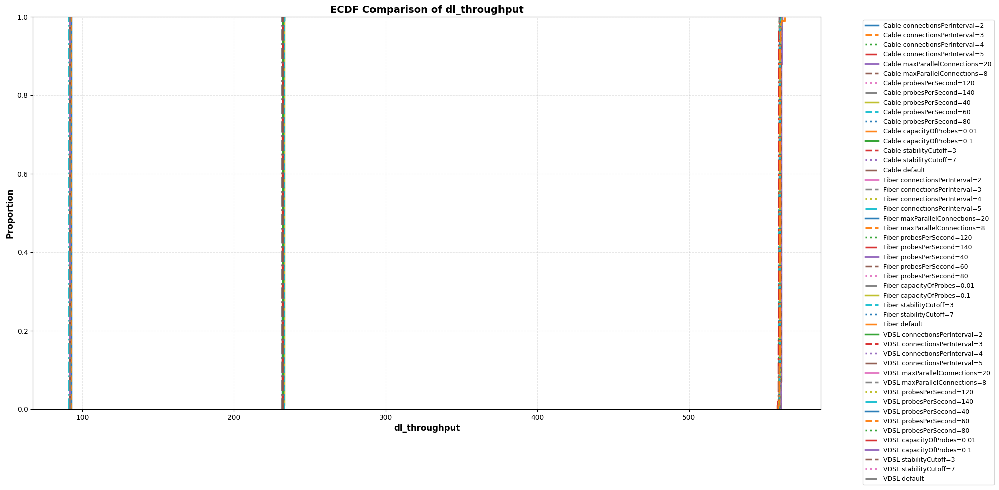

In [67]:
plot_ecdf_single(
    df_clean,
    'dl_throughput',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

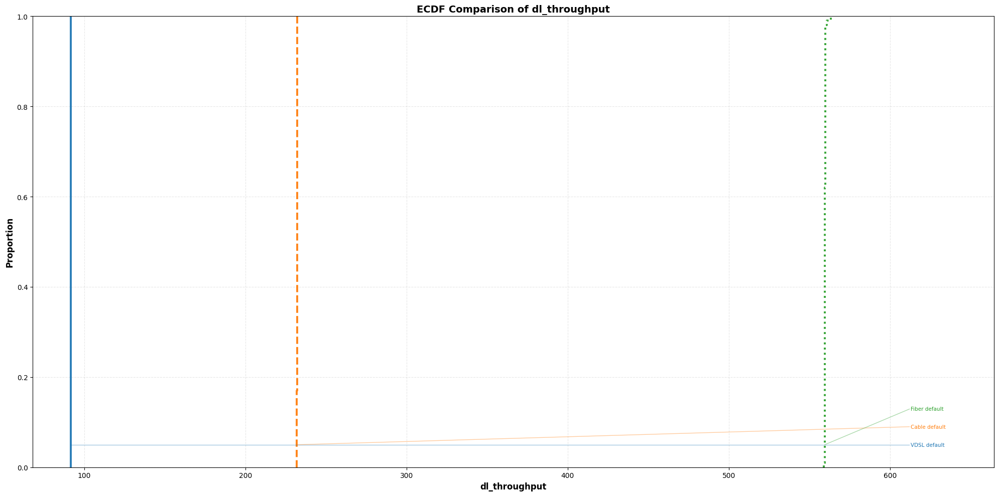

In [68]:

plot_ecdf_single_label(
    df_clean,
    'dl_throughput',
    environments=environments,
    parameters=['intervalDuration', 'default'],
    label_anchor=0.05
)

## download connections

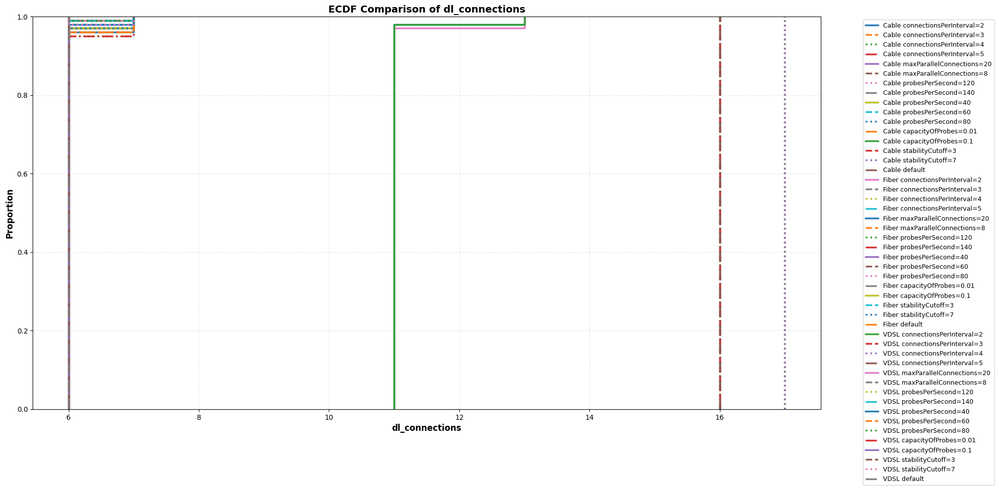

In [69]:
plot_ecdf_single(
    df_clean,
    'dl_connections',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

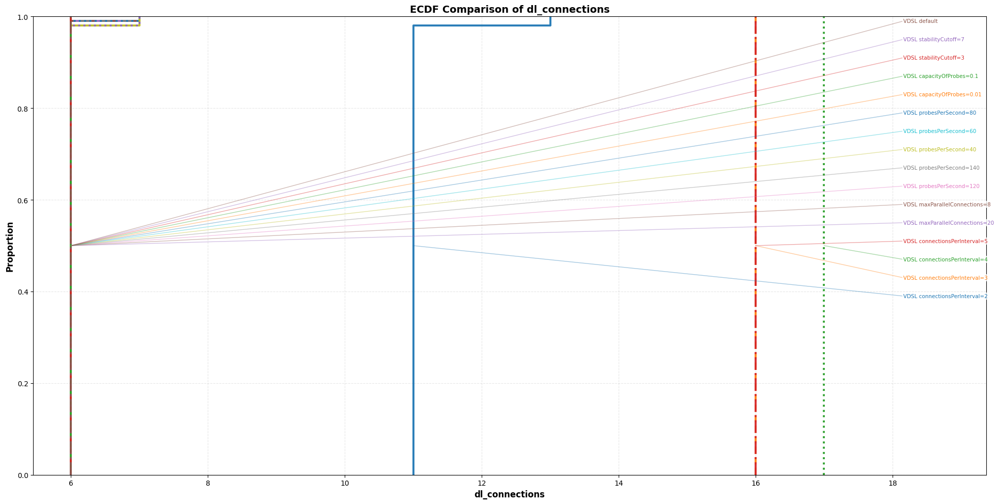

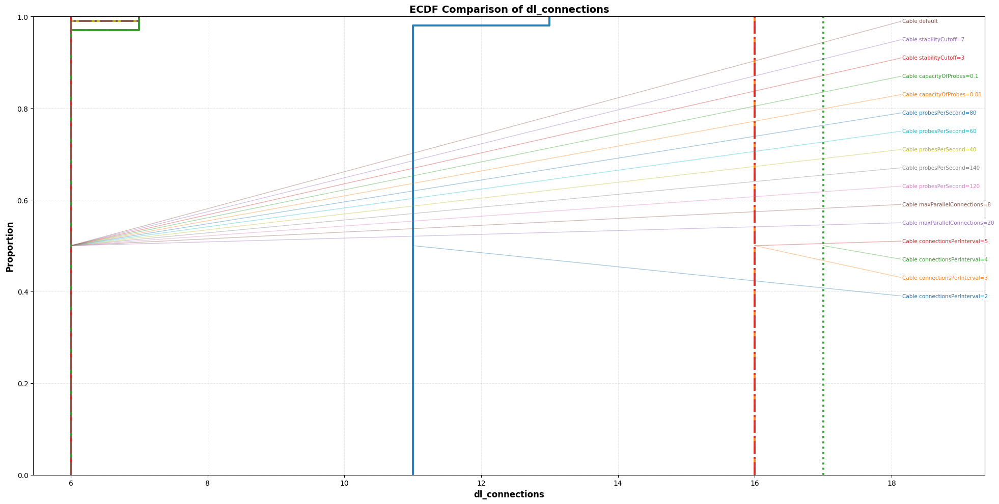

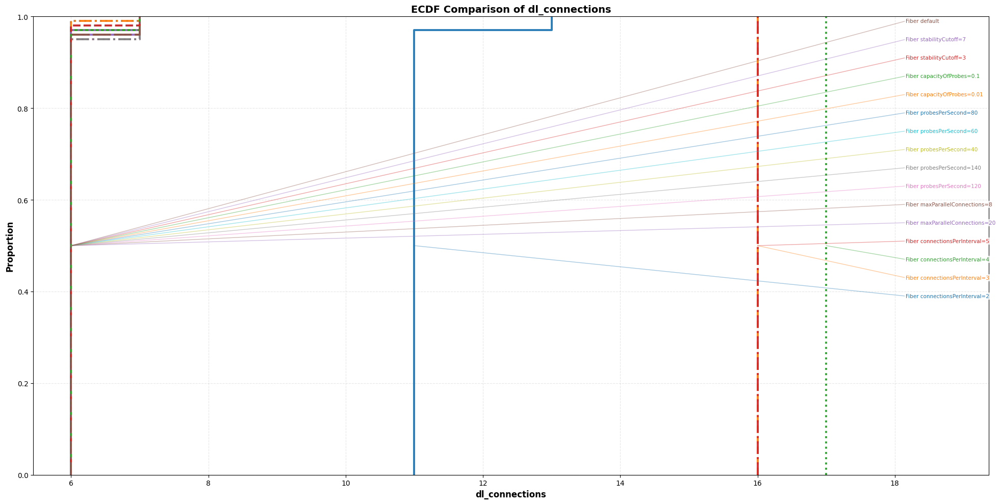

In [70]:
for env in environments:
    plot_ecdf_single_label(
        df_clean,
        'dl_connections',
        environments=[env],
        parameters=relevant_parameters+['default']
    )

## download maximum path-mtu

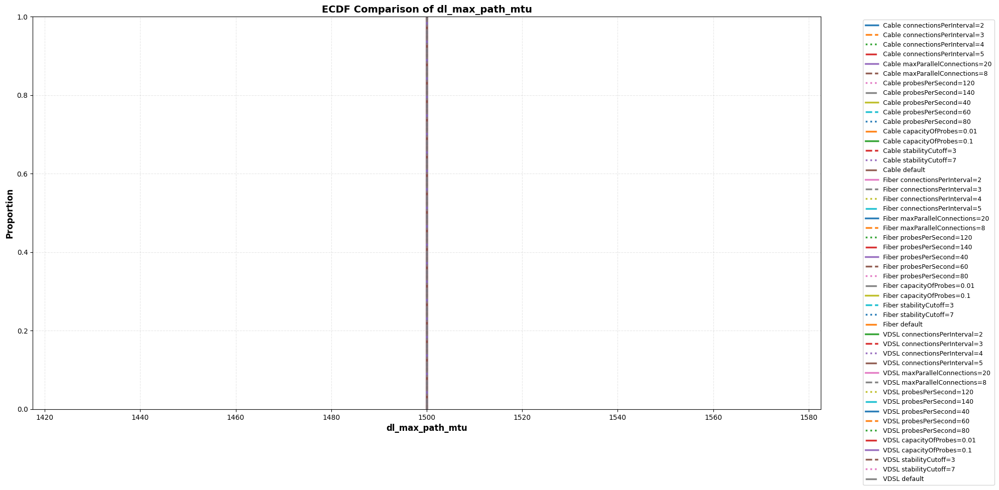

In [71]:
plot_ecdf_single(
    df_clean,
    'dl_max_path_mtu',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

## download maximum send-mss

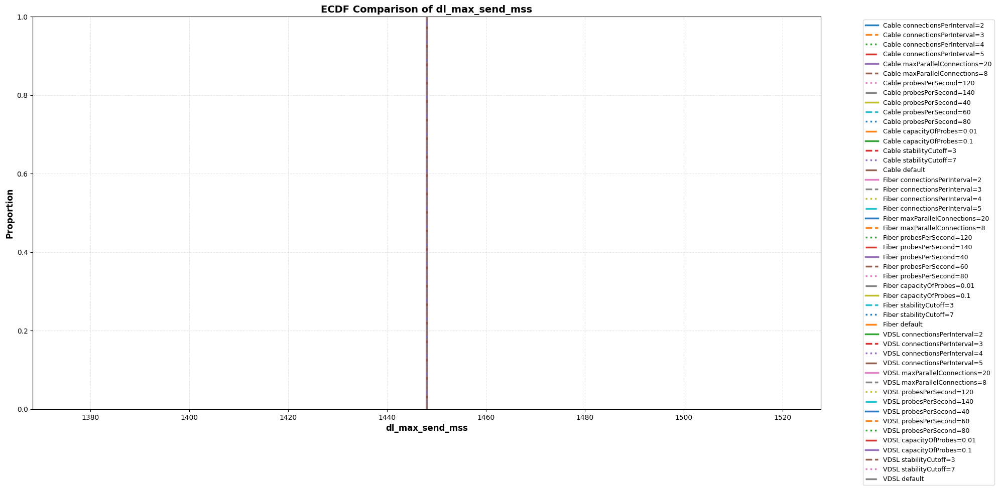

In [72]:
plot_ecdf_single(
    df_clean,
    'dl_max_send_mss',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

## download maximum receive-mss

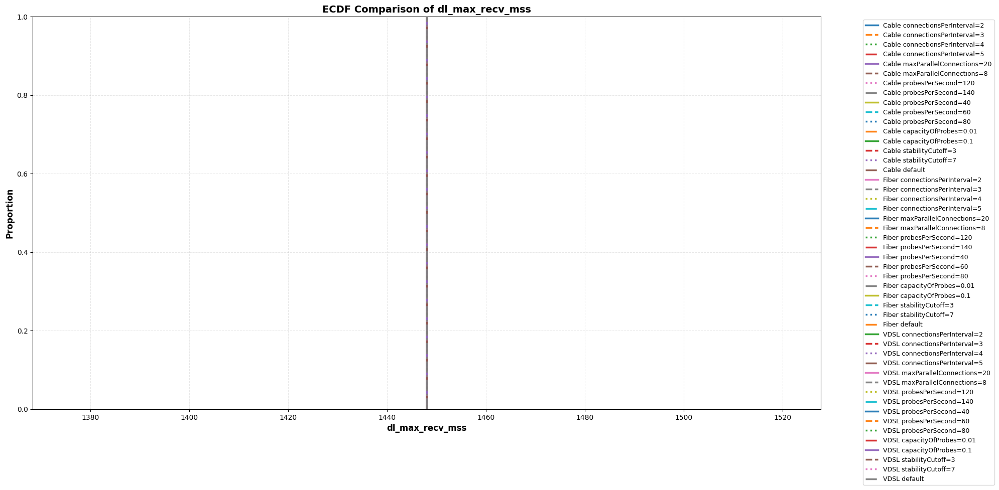

In [73]:
plot_ecdf_single(
    df_clean,
    'dl_max_recv_mss',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

## download retransmissions

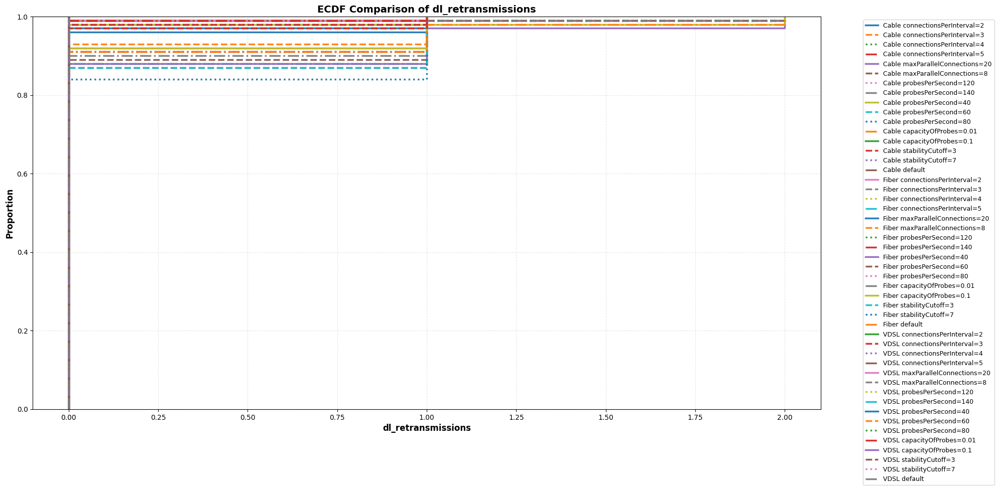

In [74]:
plot_ecdf_single(
    df_clean,
    'dl_retransmissions',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

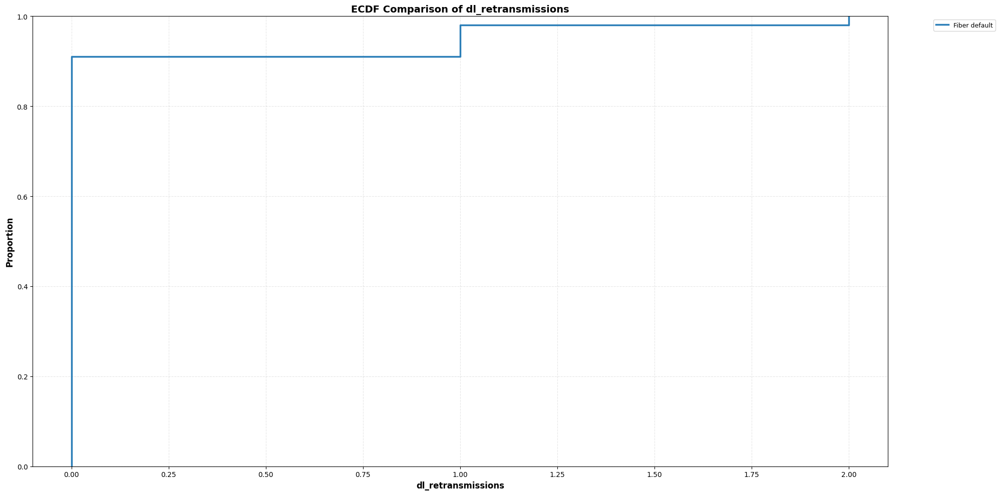

In [75]:
plot_ecdf_single(
    df_clean,
    'dl_retransmissions',
    environments=['Fiber'],
    parameters=['intervalDuration','default']
)

## download reorder

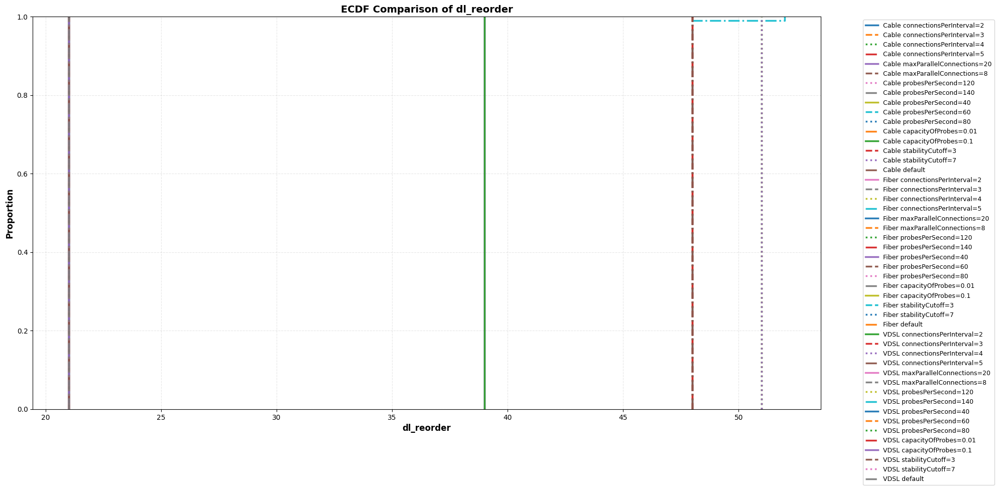

In [76]:
plot_ecdf_single(
    df_clean,
    'dl_reorder',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

## download average rtt

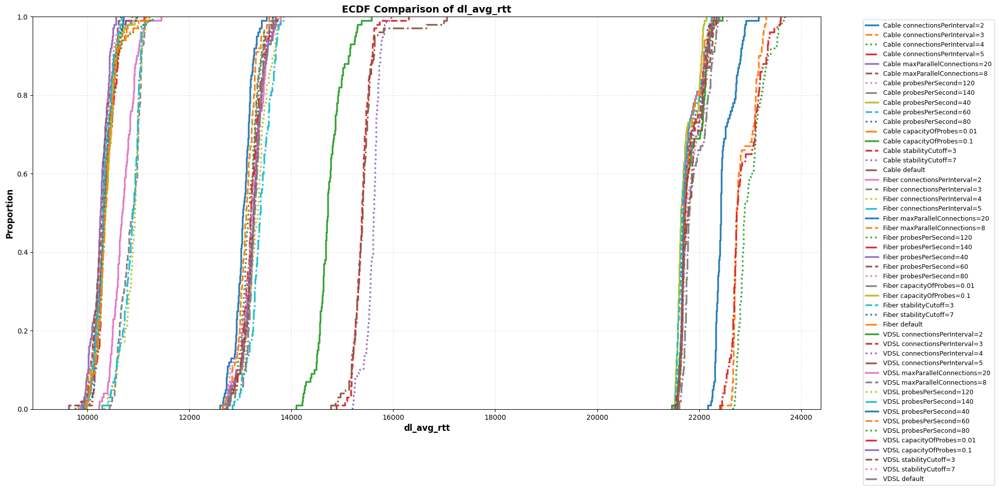

In [77]:
plot_ecdf_single(
    df_clean,
    'dl_avg_rtt',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

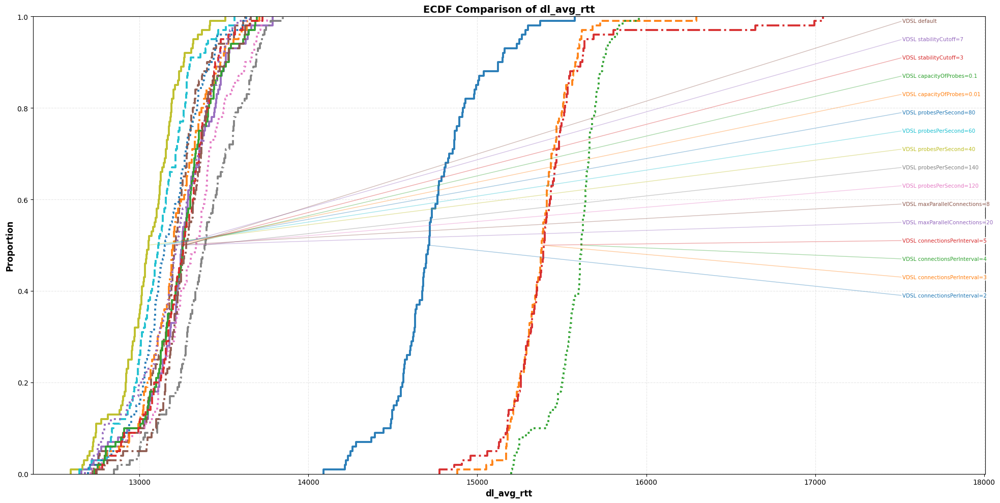

In [78]:
plot_ecdf_single_label(
    df_clean,
    'dl_avg_rtt',
    environments=['VDSL'],
    parameters=relevant_parameters+['default']
)

## download rpm p

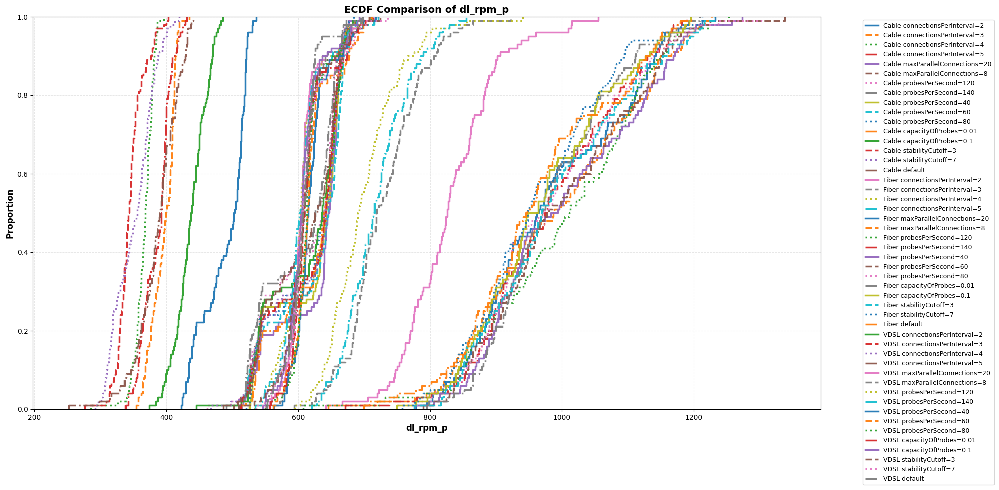

In [79]:
plot_ecdf_single(
    df_clean,
    'dl_rpm_p',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

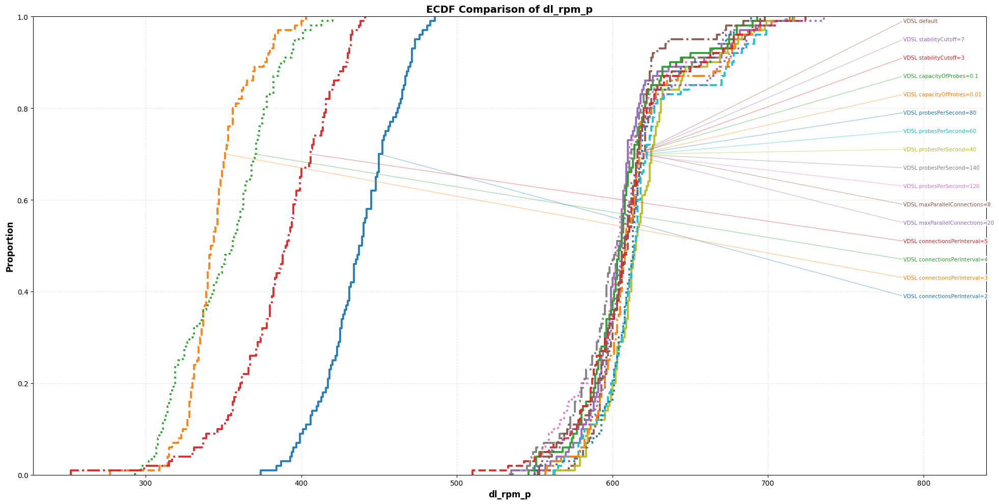

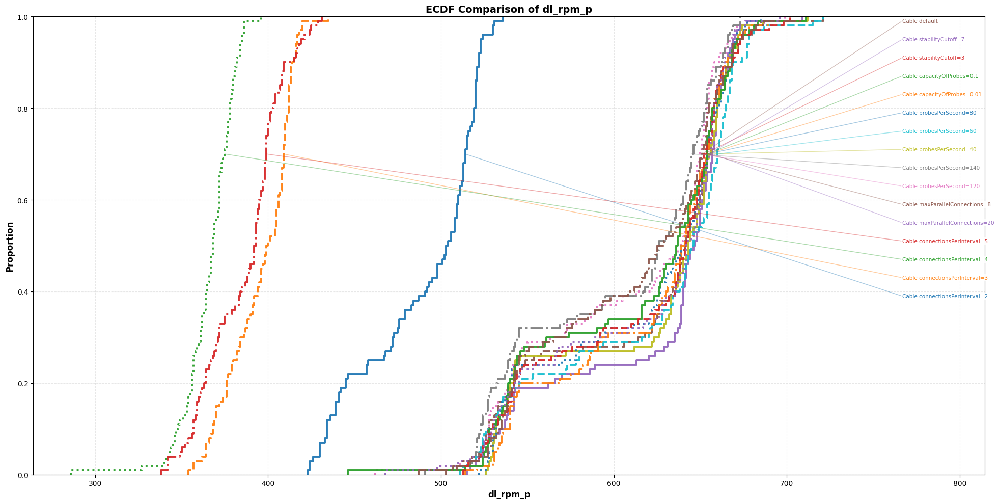

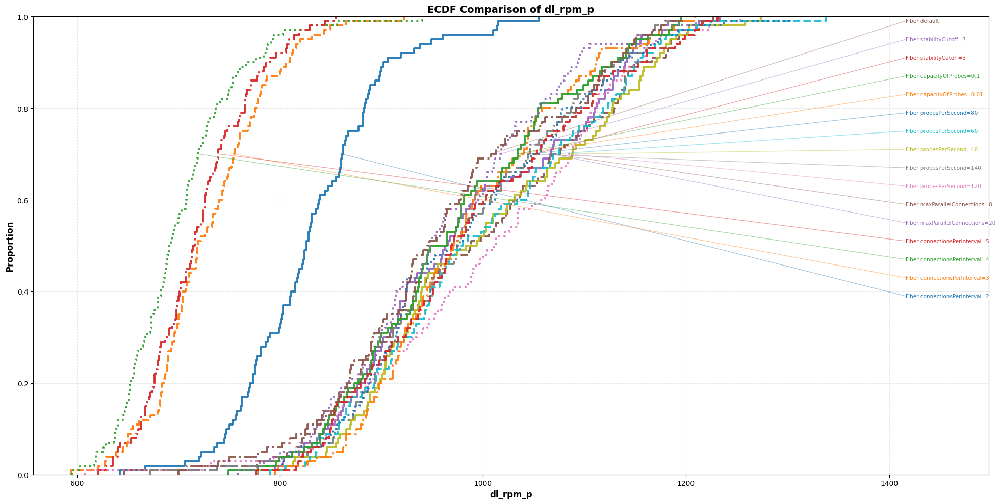

In [80]:
for env in environments:
    plot_ecdf_single_label(
    df_clean,
    'dl_rpm_p',
    environments=[env],
    parameters=relevant_parameters+['default'],
    label_anchor=0.7
)

## download rpm trimmed

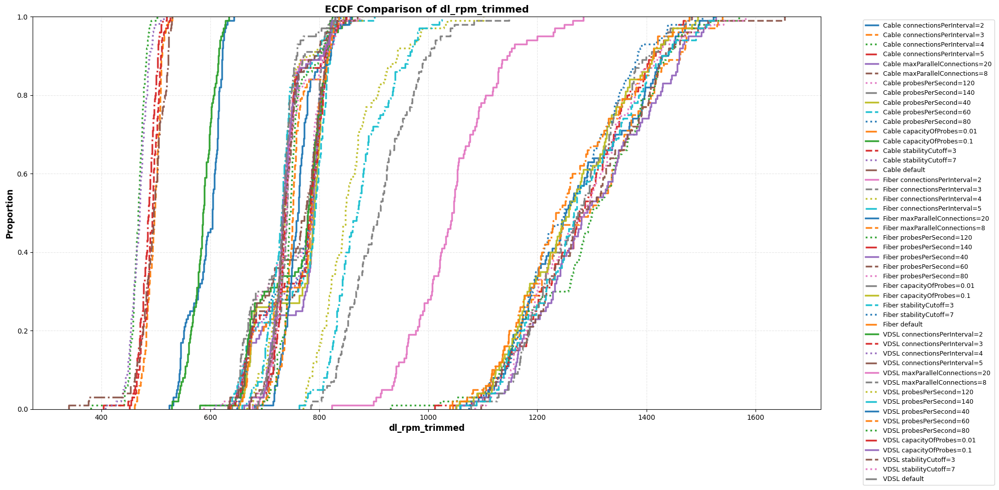

In [81]:
plot_ecdf_single(
    df_clean,
    'dl_rpm_trimmed',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

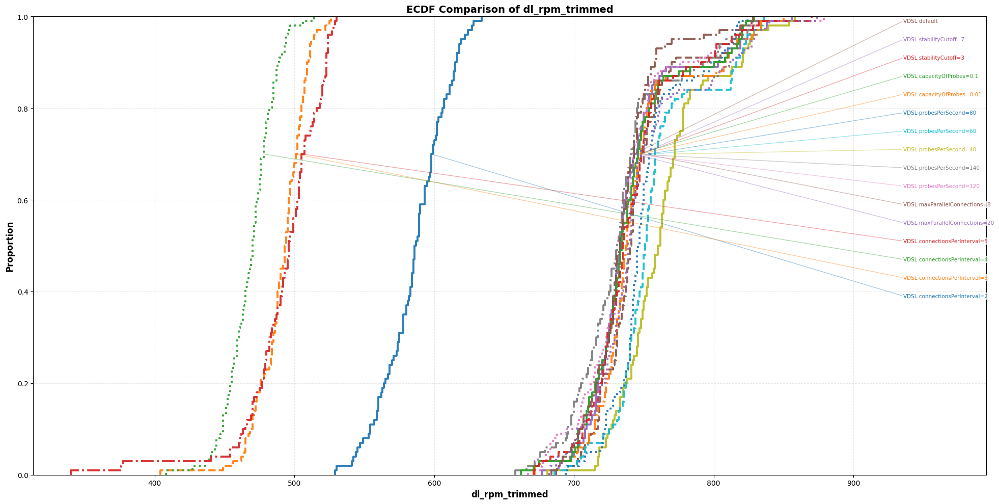

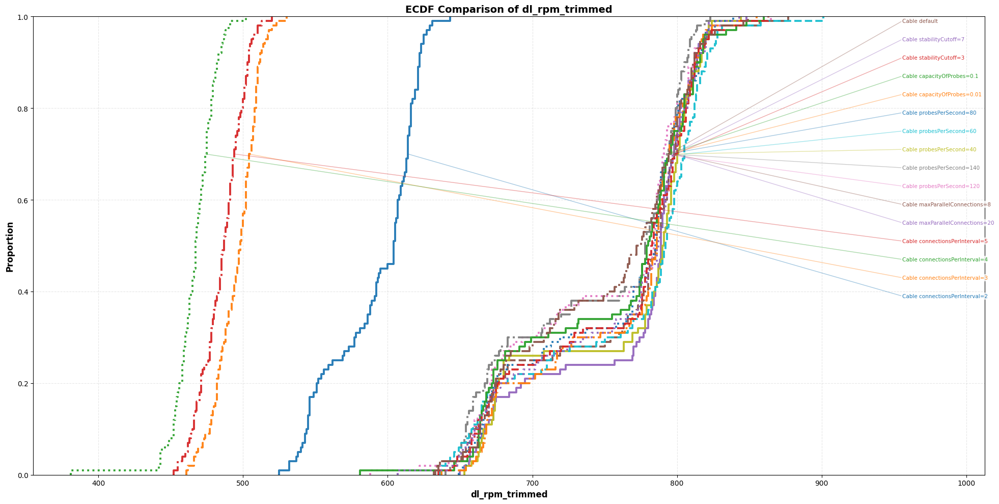

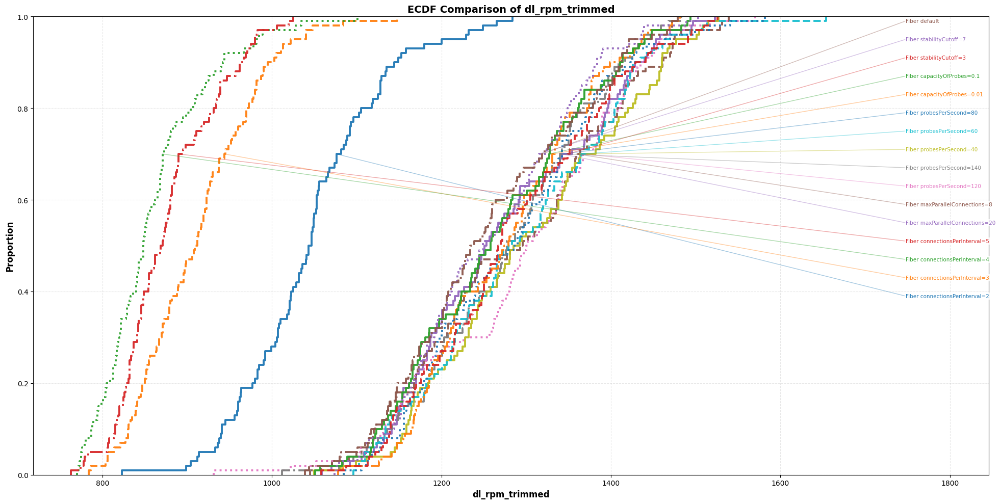

In [82]:
for env in environments:
    plot_ecdf_single_label(
    df_clean,
    'dl_rpm_trimmed',
    environments=[env],
    parameters=relevant_parameters+['default'],
    label_anchor=0.7
)

# upload stats

## upload throughput

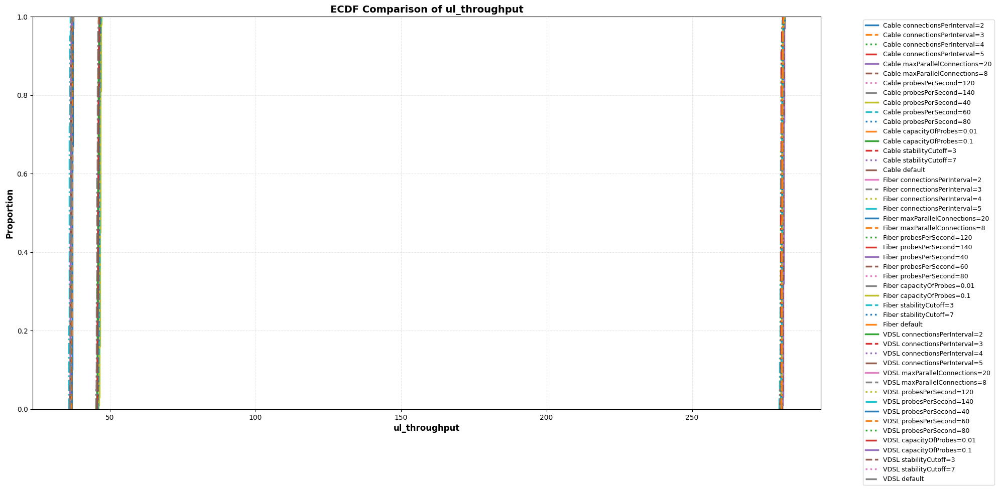

In [83]:
plot_ecdf_single(
    df_clean,
    'ul_throughput',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

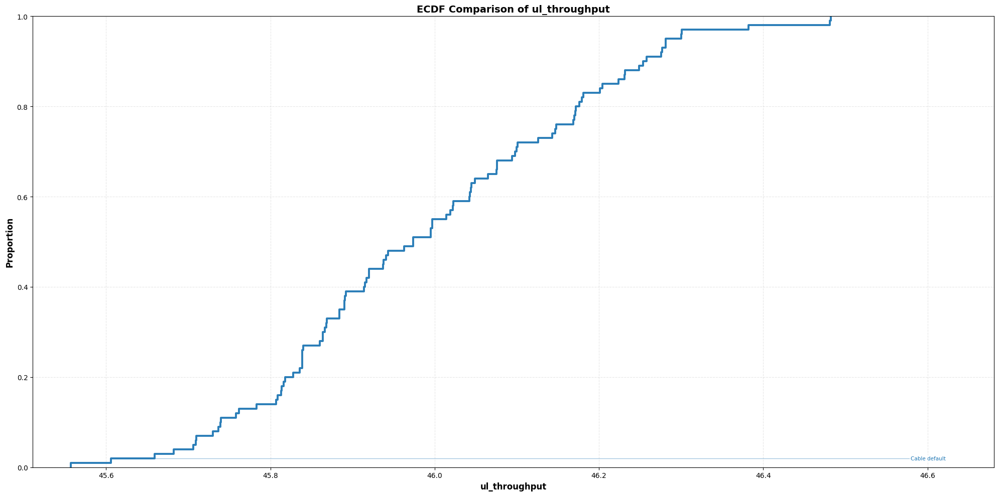

In [84]:
plot_ecdf_single_label(
    df_clean,
    'ul_throughput',
    environments=['Cable'],
    parameters=['default', 'intervalDuration'],
    label_anchor=0.02
)

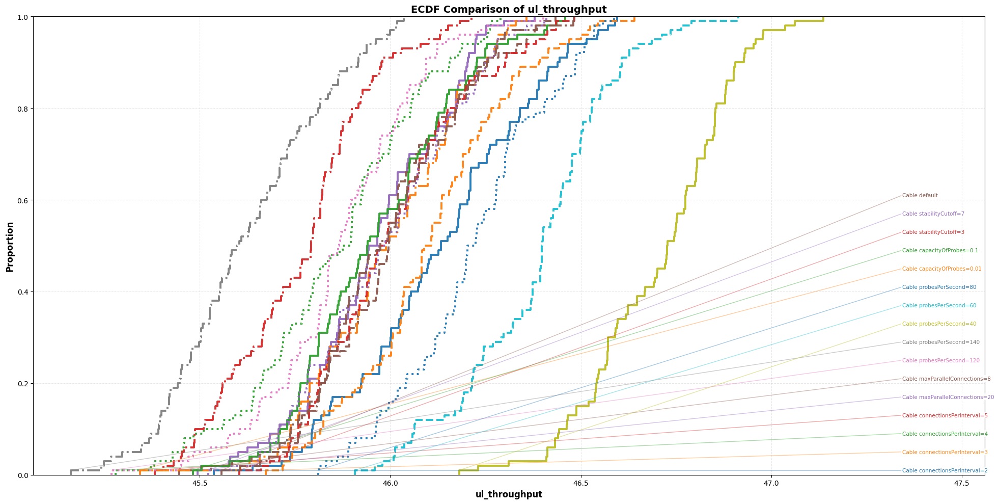

In [85]:
plot_ecdf_single_label(
    df_clean,
    'ul_throughput',
    environments=['Cable'],
    parameters=relevant_parameters+['default'],
    label_anchor=0.01
)

## upload parallel connections

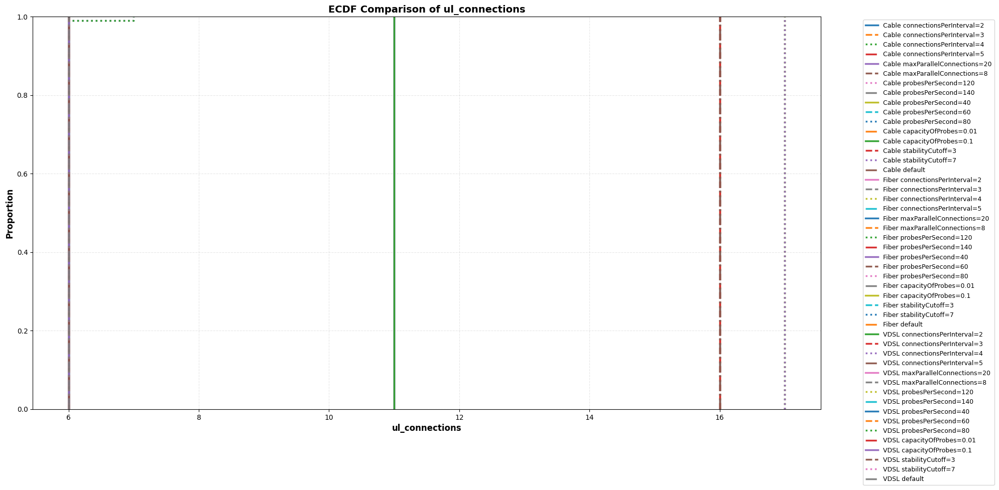

In [86]:
plot_ecdf_single(
    df_clean,
    'ul_connections',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

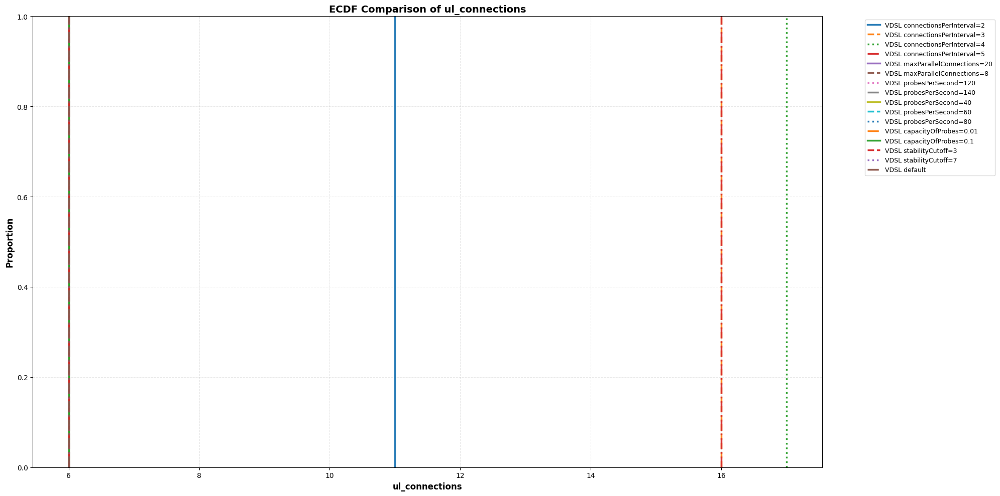

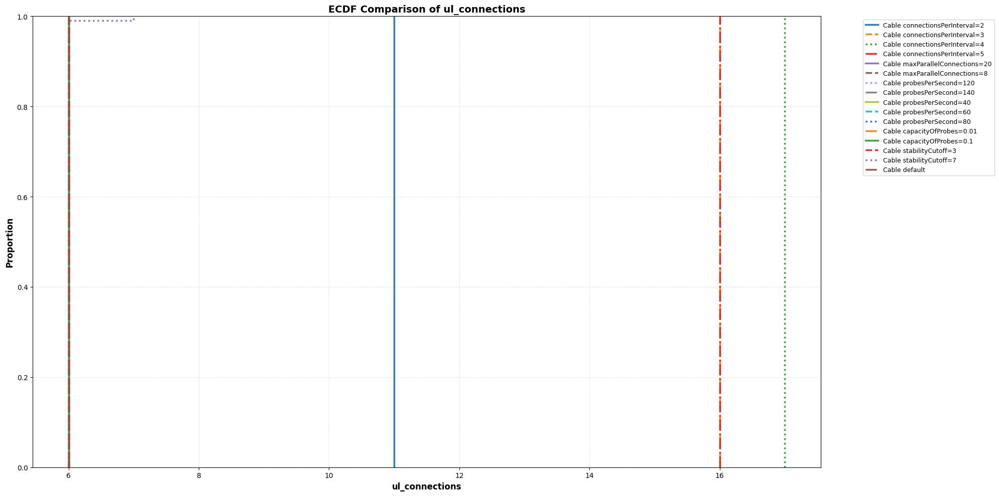

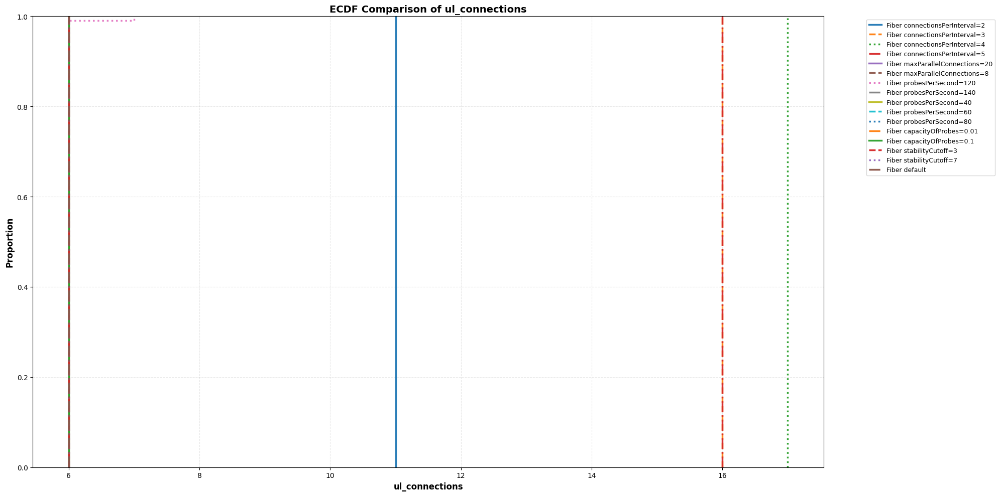

In [87]:
for env in environments:
    plot_ecdf_single(
    df_clean,
    'ul_connections',
    environments=[env],
    parameters=relevant_parameters+['default']
)

## upload maximum path-mtu

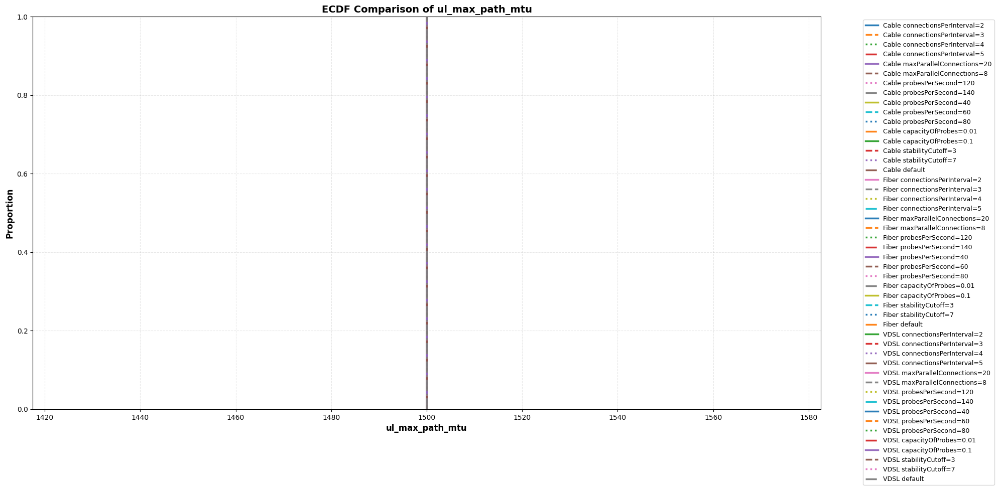

In [88]:
plot_ecdf_single(
    df_clean,
    'ul_max_path_mtu',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

## upload maximum send-mss

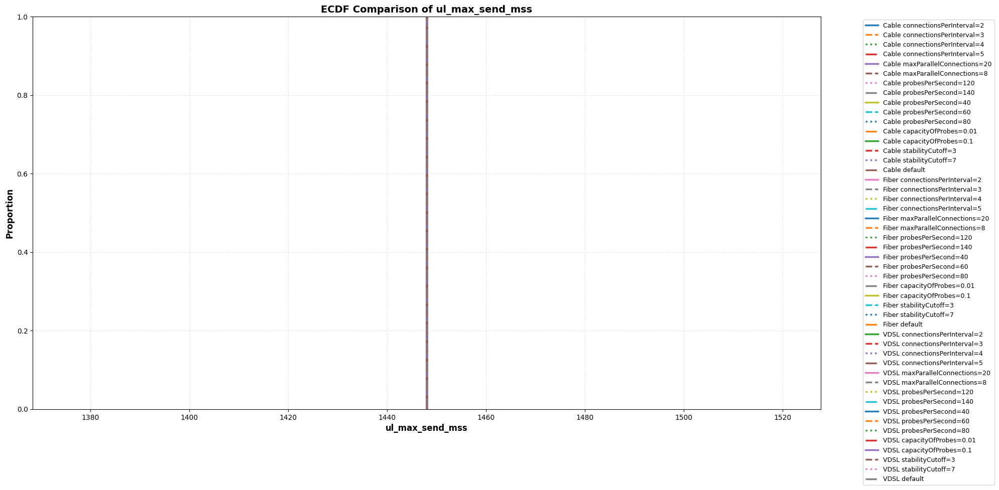

In [89]:
plot_ecdf_single(
    df_clean,
    'ul_max_send_mss',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

## upload maximum receive-mss

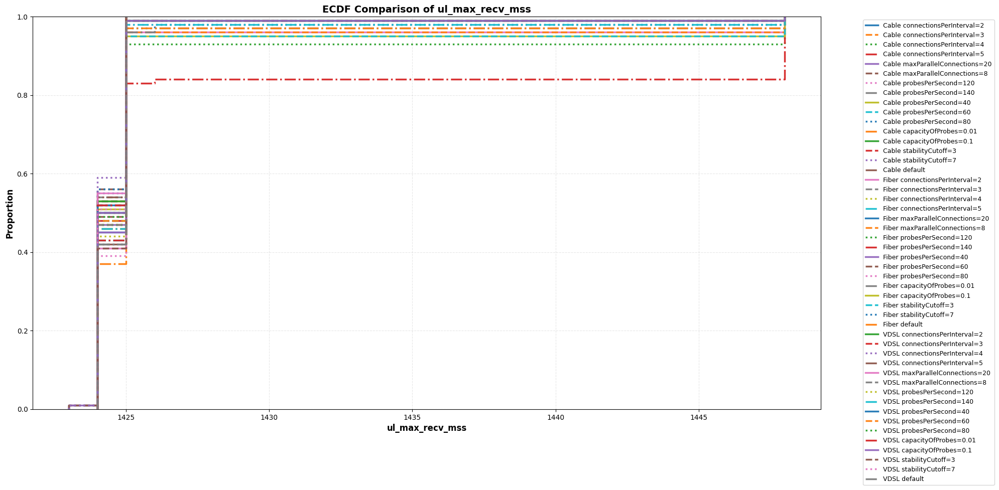

In [90]:
plot_ecdf_single(
    df_clean,
    'ul_max_recv_mss',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

## upload retransmissions

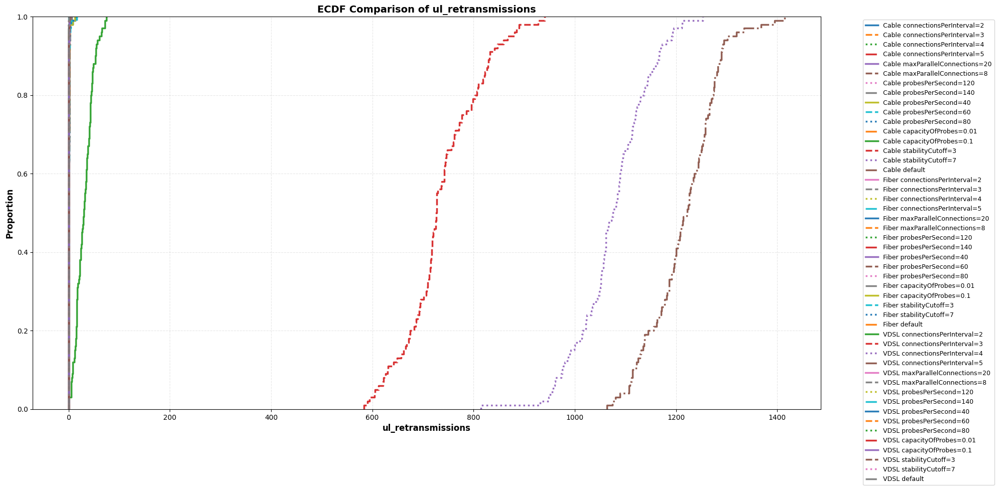

In [91]:
plot_ecdf_single(
    df_clean,
    'ul_retransmissions',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

## upload reorder

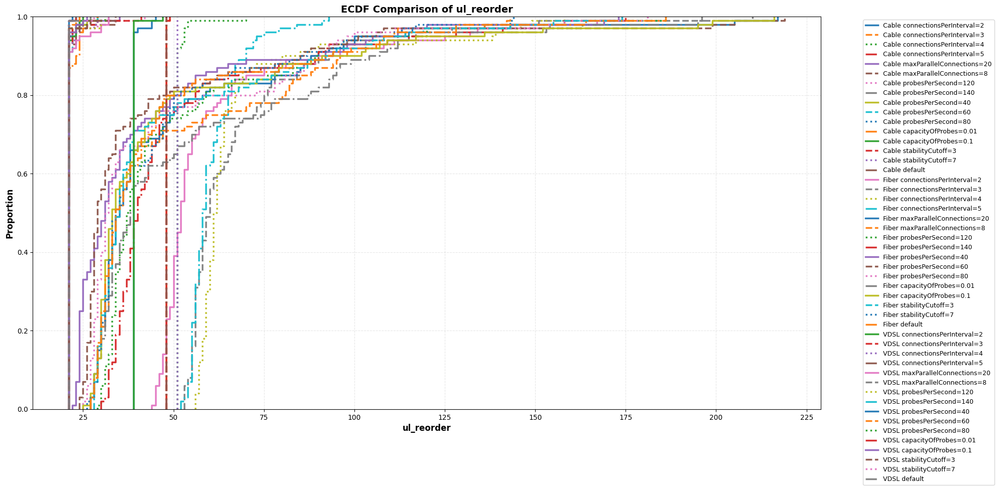

In [92]:
plot_ecdf_single(
    df_clean,
    'ul_reorder',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

## upload average rtt

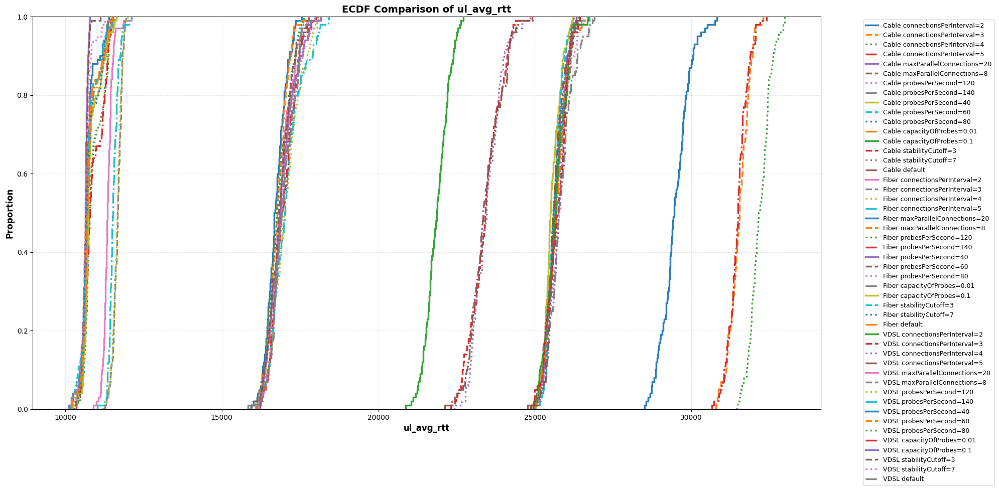

In [93]:
plot_ecdf_single(
    df_clean,
    'ul_avg_rtt',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

## upload rpm p

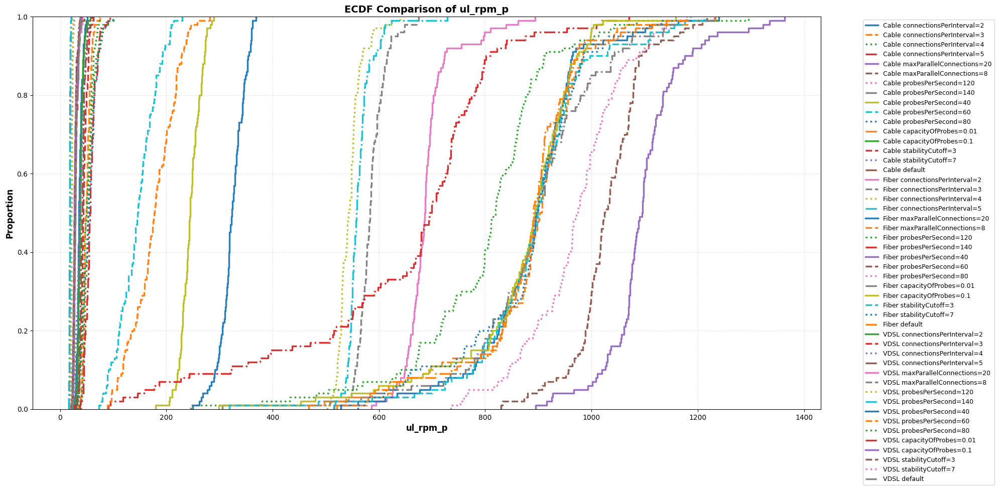

In [94]:
plot_ecdf_single(
    df_clean,
    'ul_rpm_p',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

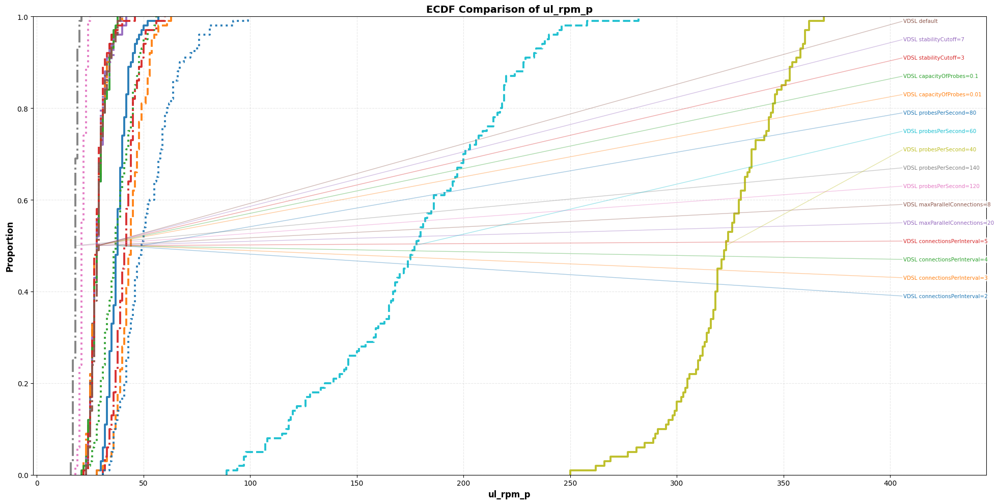

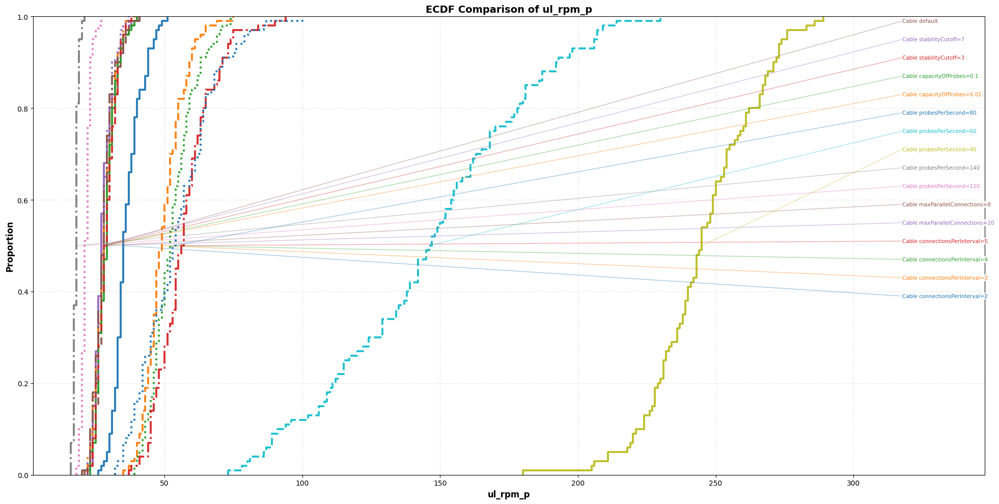

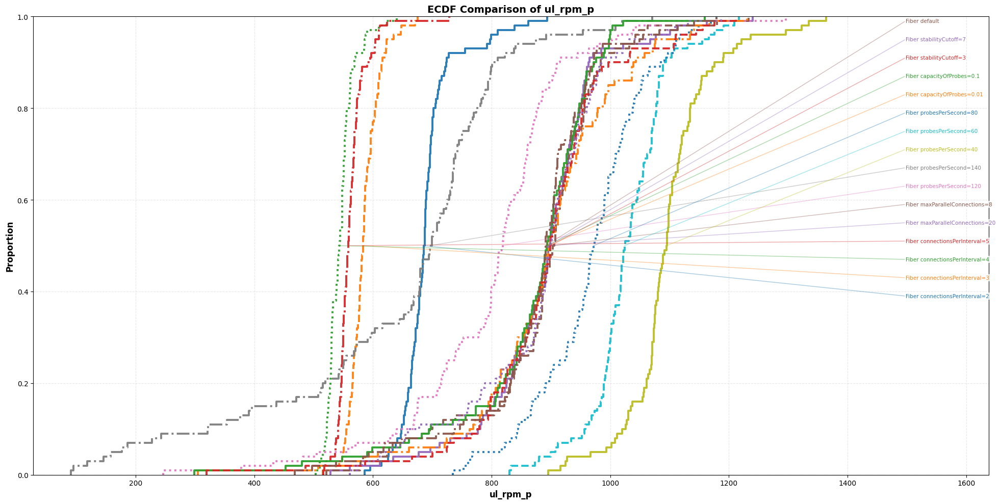

In [95]:
for env in environments:
    plot_ecdf_single_label(
    df_clean,
    'ul_rpm_p',
    environments=[env],
    parameters=relevant_parameters+['default']
)

## upload rpm trimmed

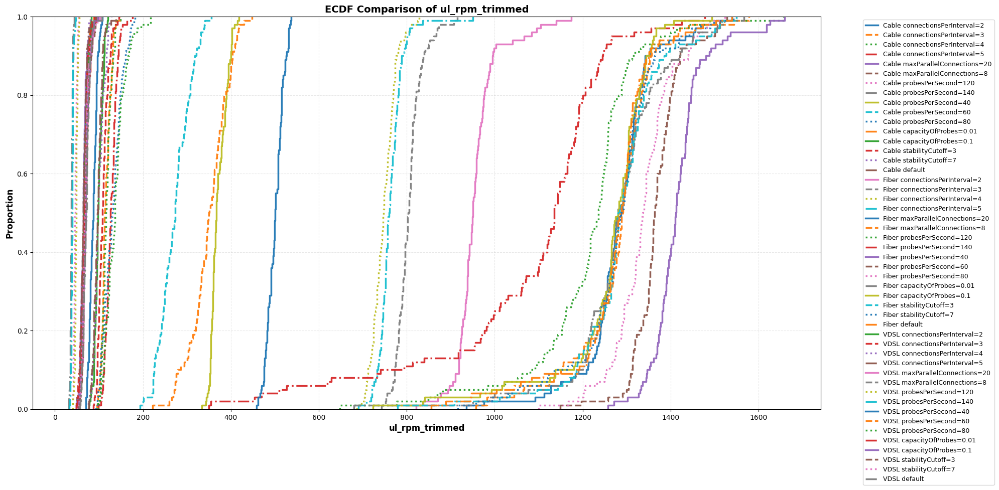

In [96]:
plot_ecdf_single(
    df_clean,
    'ul_rpm_trimmed',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

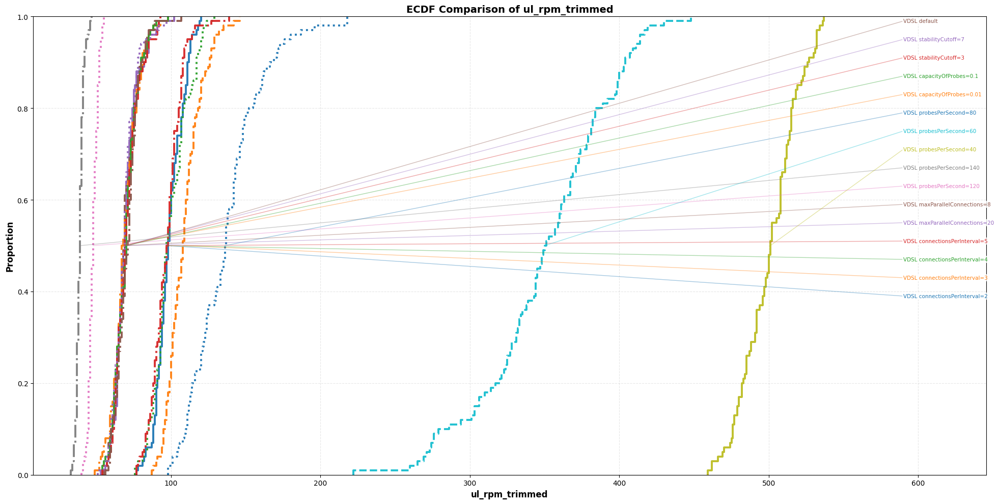

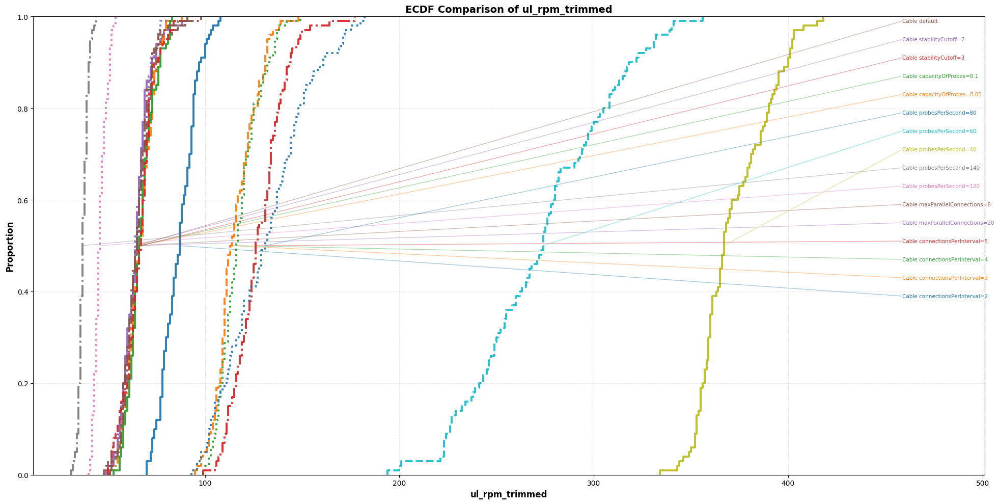

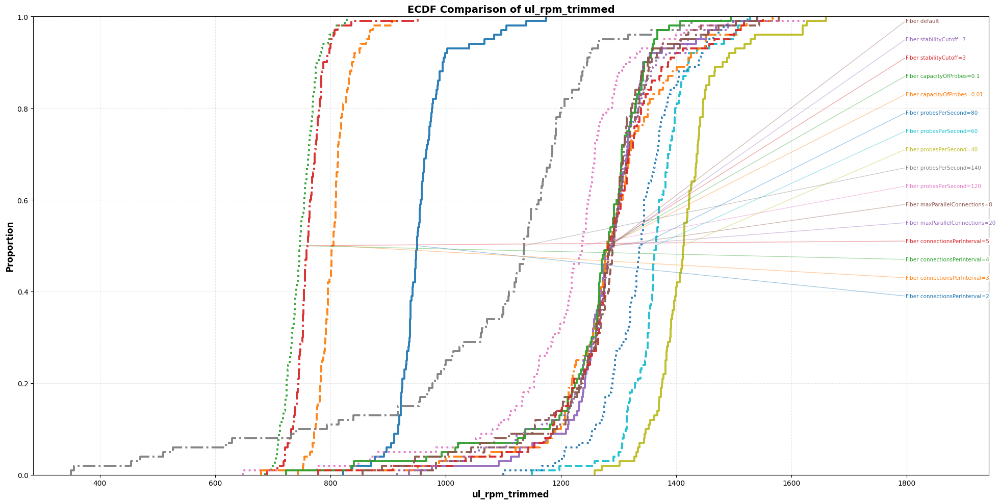

In [97]:
for env in environments:
    plot_ecdf_single_label(
    df_clean,
    'ul_rpm_trimmed',
    environments=[env],
    parameters=relevant_parameters+['default']
)

# final stats

## final rpm p

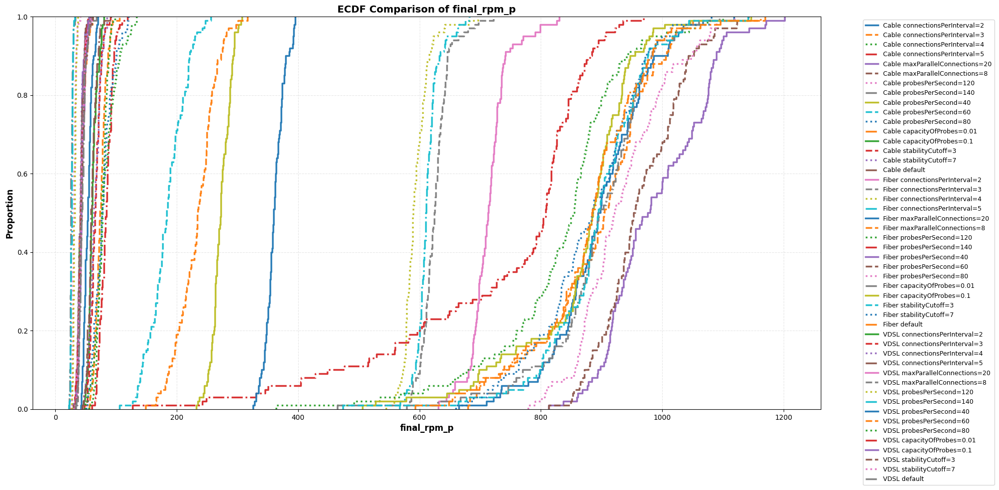

In [98]:
plot_ecdf_single(
    df_clean,
    'final_rpm_p',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

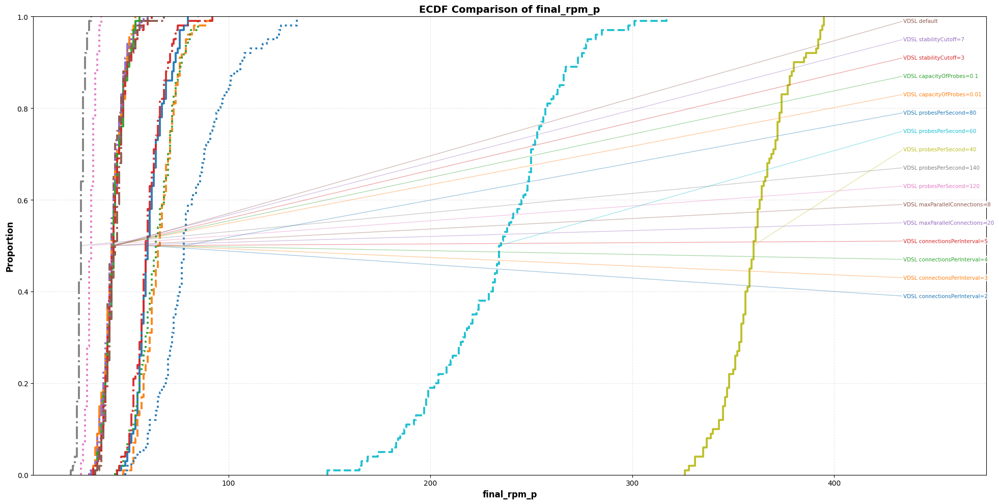

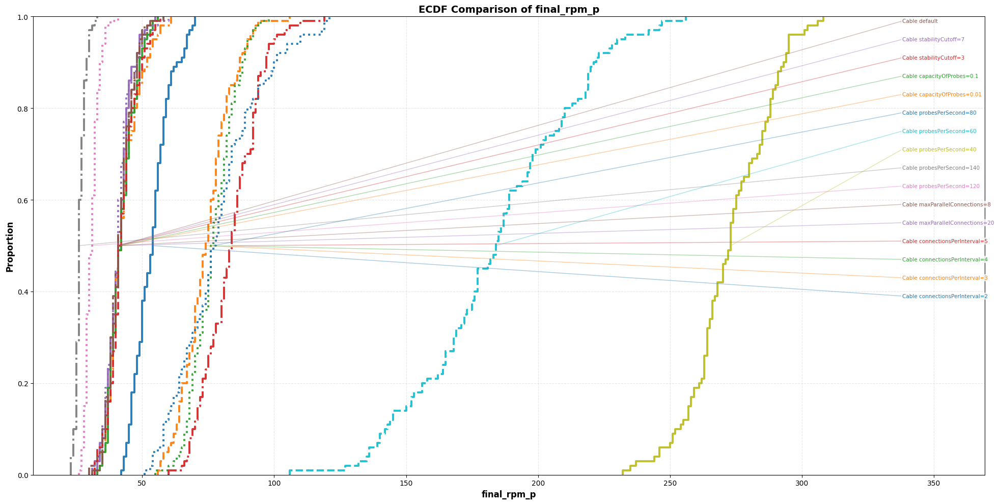

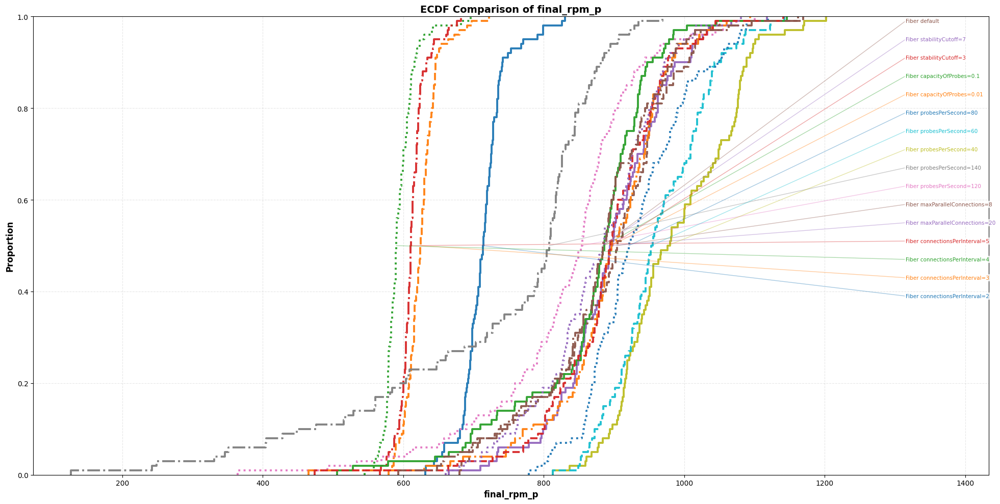

In [99]:
for env in environments:
    plot_ecdf_single_label(
    df_clean,
    'final_rpm_p',
    environments=[env],
    parameters=relevant_parameters+['default']
)

# final rpm trimmed

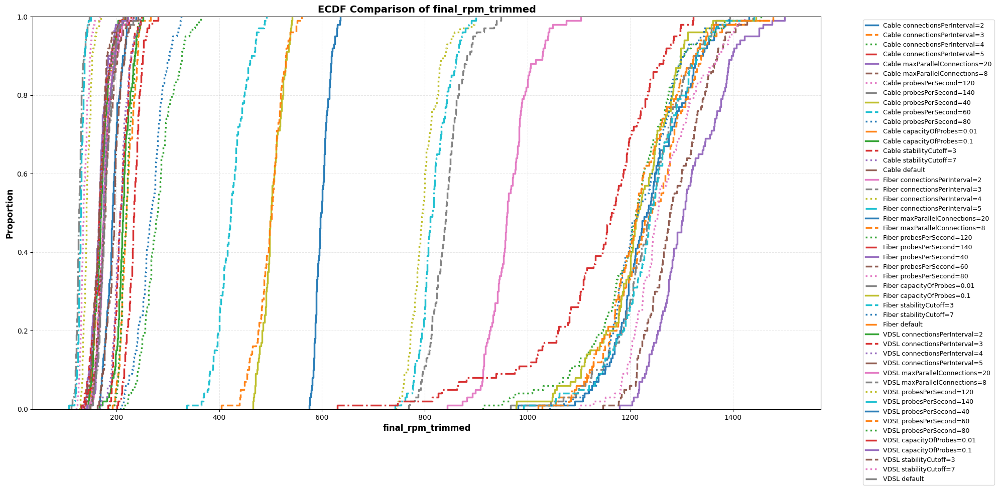

In [100]:
plot_ecdf_single(
    df_clean,
    'final_rpm_trimmed',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

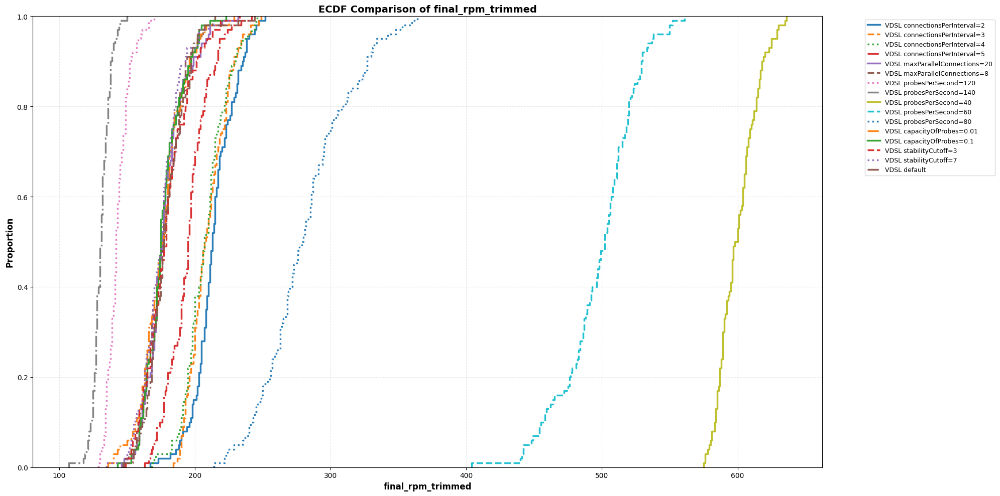

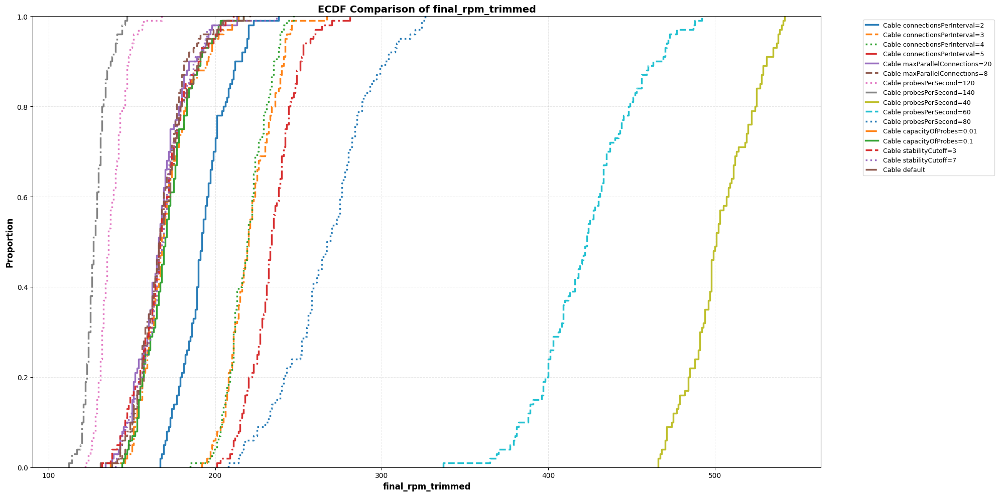

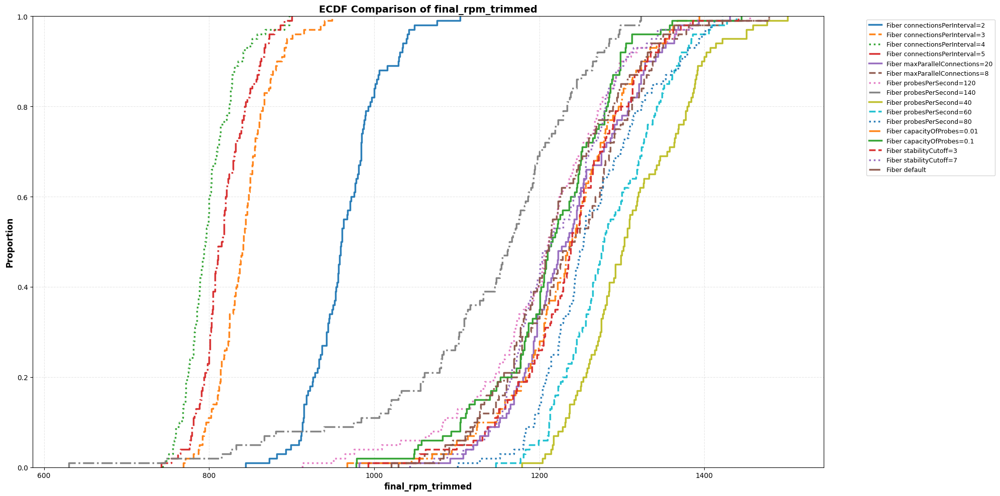

In [101]:
for env in environments:
    plot_ecdf_single(
        df_clean,
        'final_rpm_trimmed',
        environments=[env],
        parameters=relevant_parameters+['default']
    )

# relative stats

## unbound base rpm p

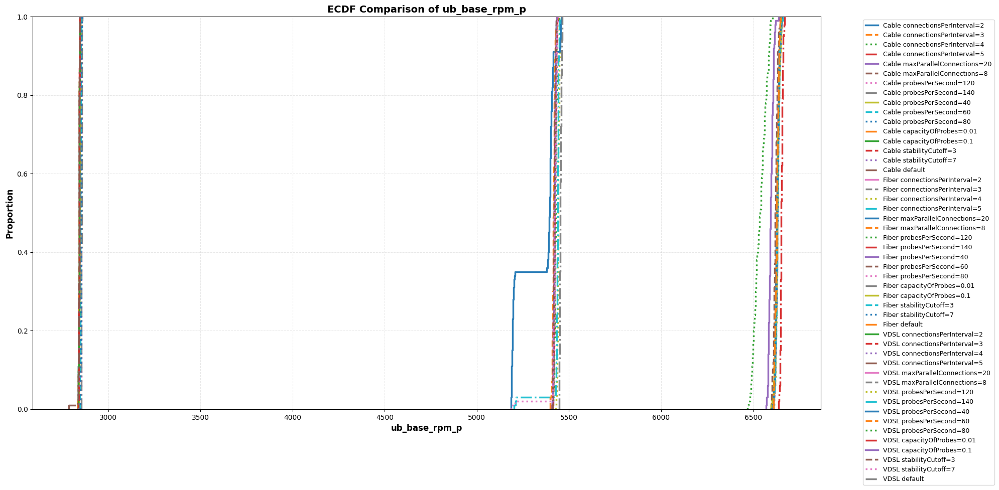

In [102]:
plot_ecdf_single(
    df_clean,
    'ub_base_rpm_p',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

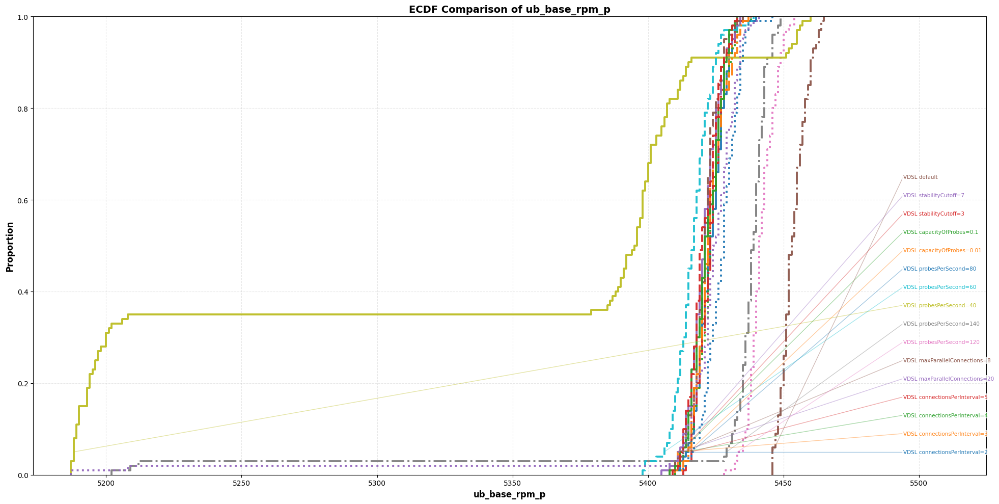

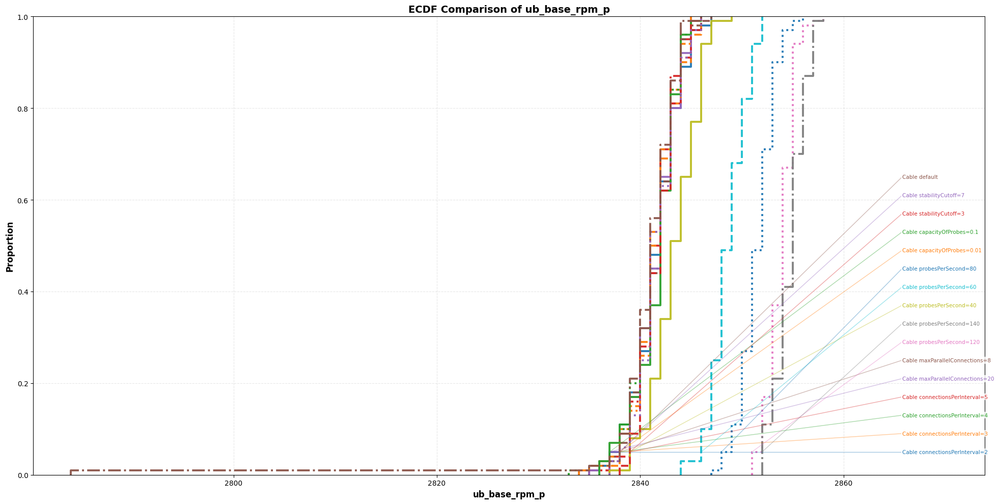

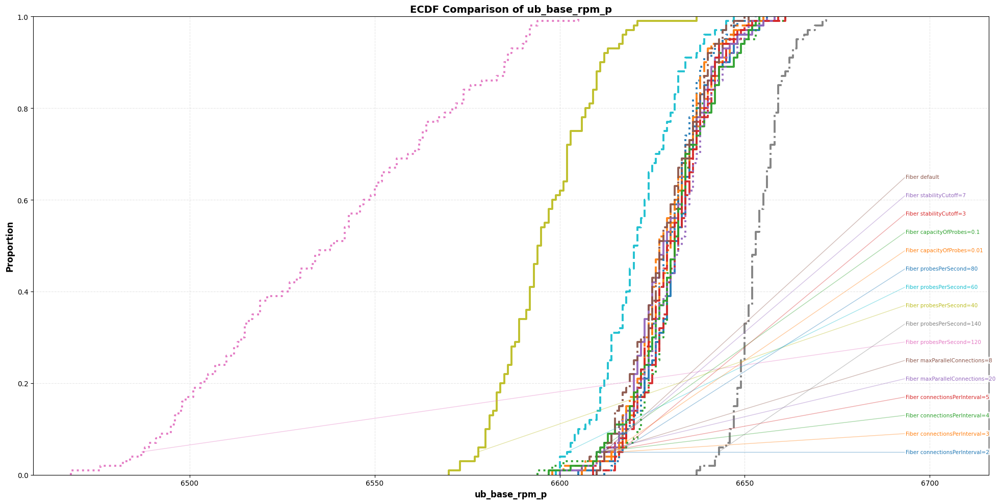

In [103]:
for env in environments:
    plot_ecdf_single_label(
    df_clean,
    'ub_base_rpm_p',
    environments=[env],
    parameters=relevant_parameters+['default'],
    label_anchor=0.05
)

## unbound base rpm trimmed

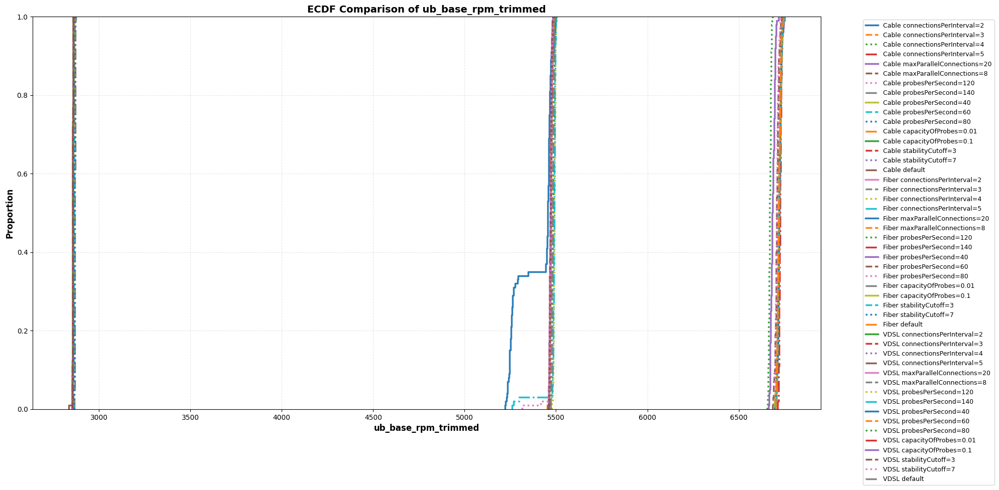

In [104]:
plot_ecdf_single(
    df_clean,
    'ub_base_rpm_trimmed',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

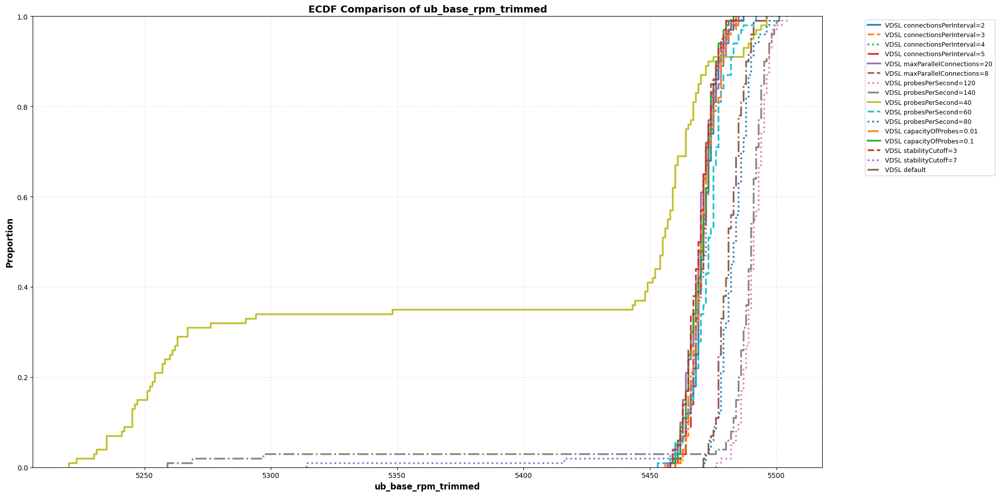

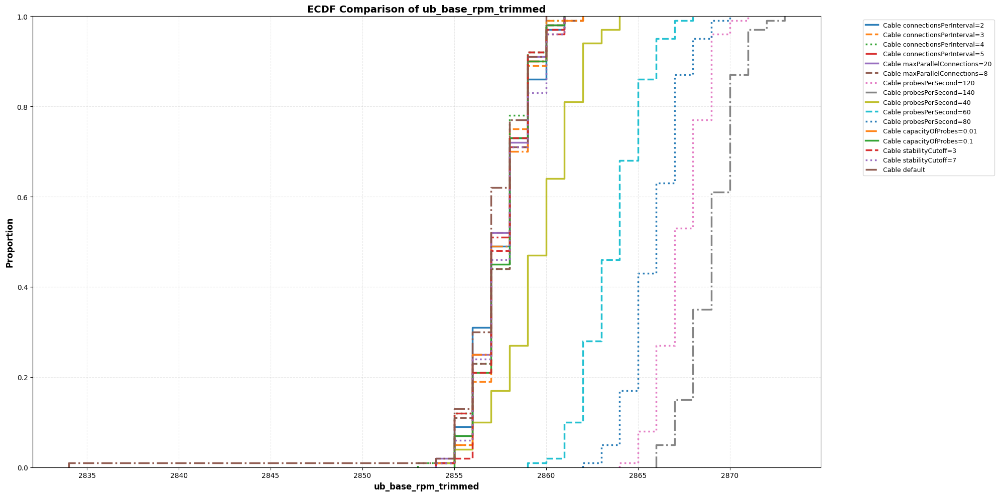

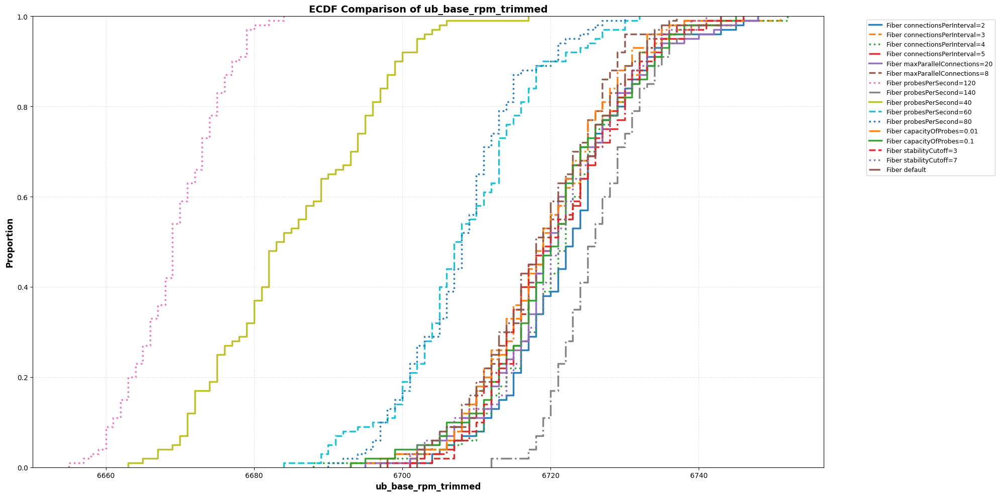

In [105]:
for env in environments:
    plot_ecdf_single(
        df_clean,
        'ub_base_rpm_trimmed',
        environments=[env],
        parameters=relevant_parameters+['default']
    )

## bound base rpm p

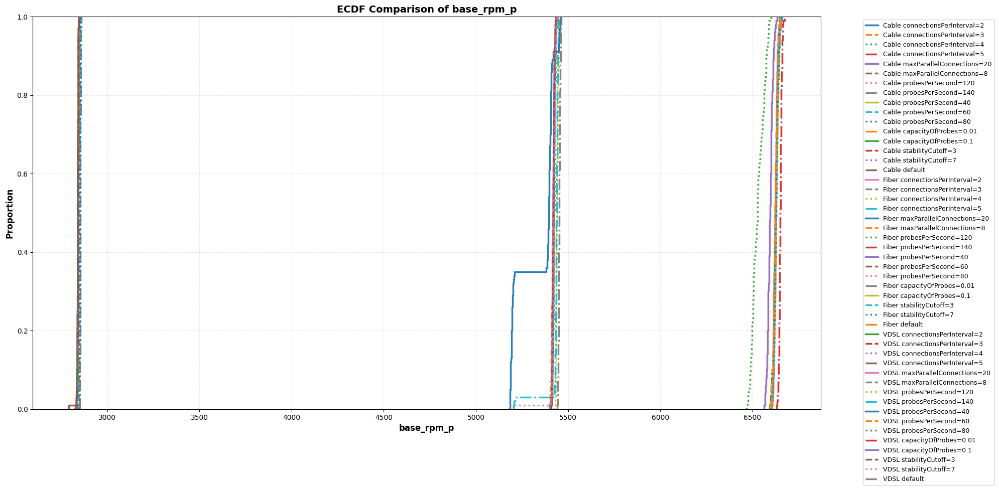

In [106]:
plot_ecdf_single(
    df_clean,
    'base_rpm_p',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

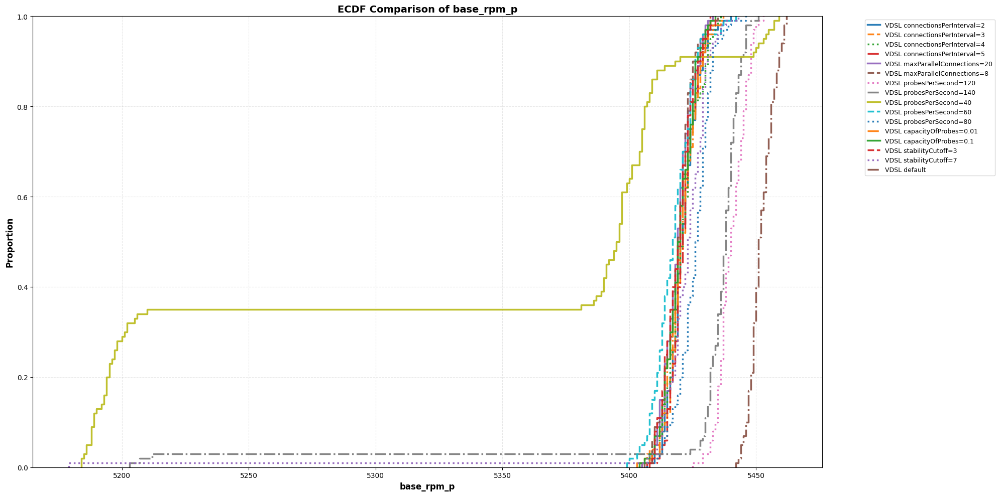

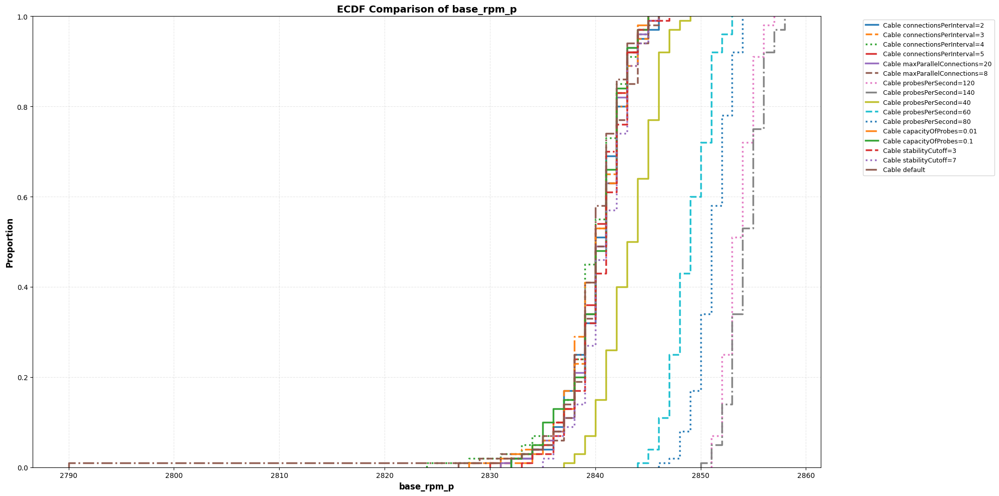

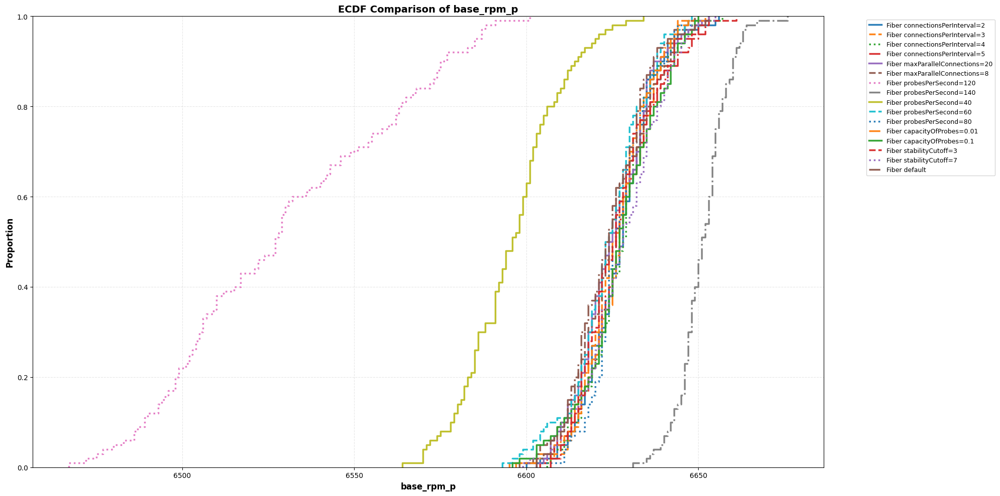

In [107]:
for env in environments:
    plot_ecdf_single(
    df_clean,
    'base_rpm_p',
    environments=[env],
    parameters=relevant_parameters+['default']
)

## bound bae rpm trimmed

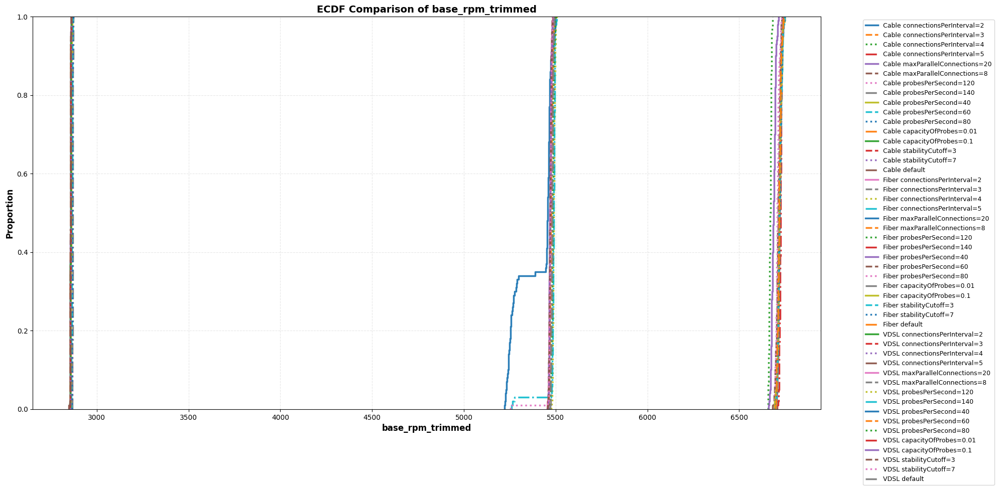

In [108]:
plot_ecdf_single(
    df_clean,
    'base_rpm_trimmed',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

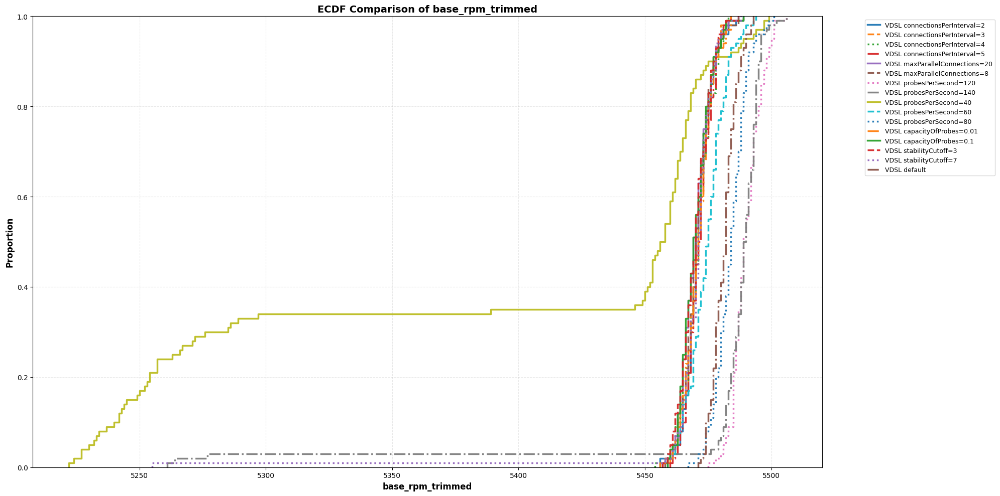

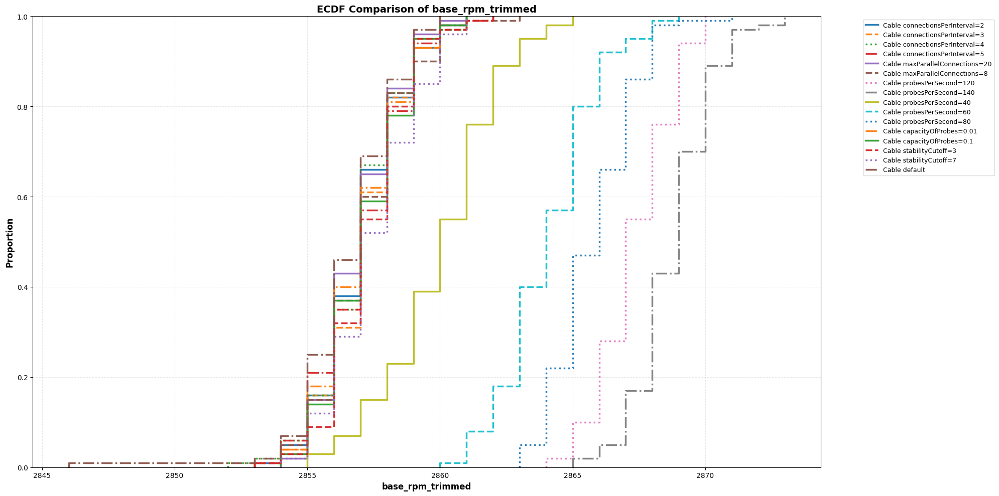

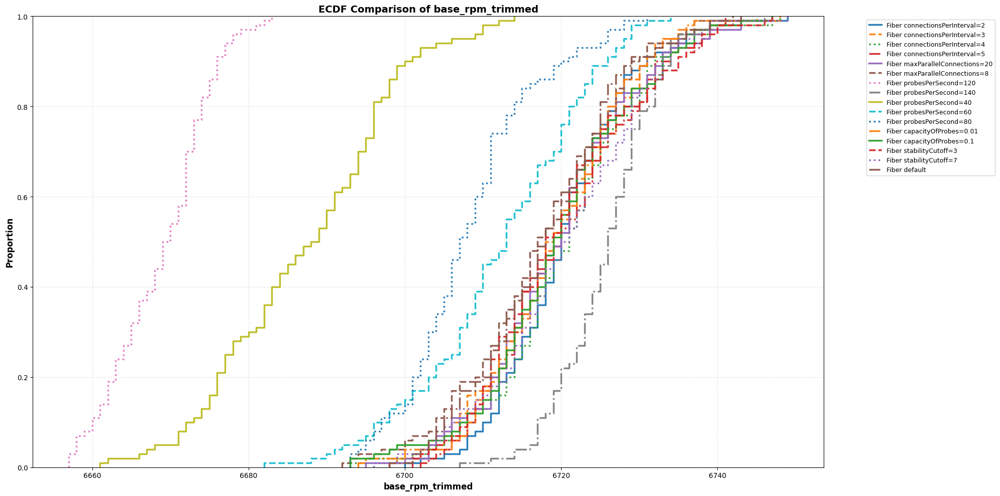

In [109]:
for env in environments:
    plot_ecdf_single(
    df_clean,
    'base_rpm_trimmed',
    environments=[env],
    parameters=relevant_parameters+['default']
)

## working condition effect on rpm p

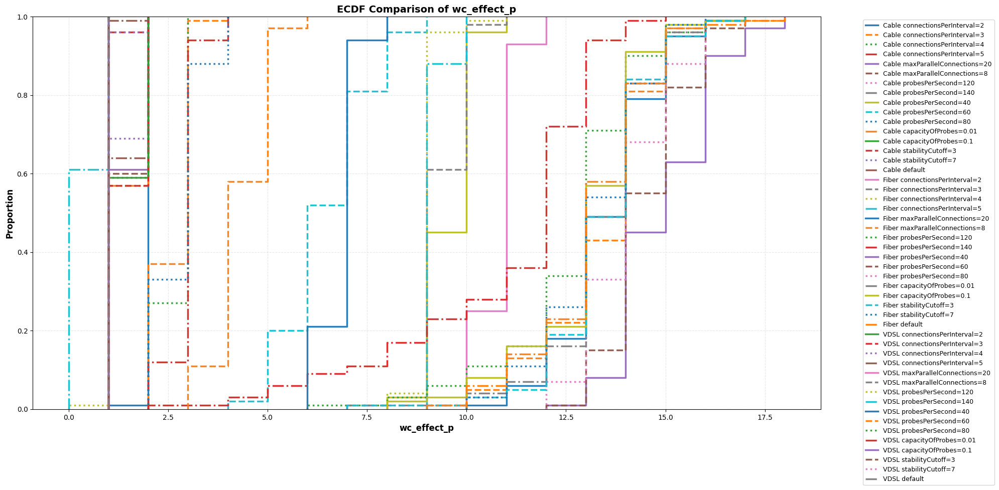

In [110]:
plot_ecdf_single(
    df_clean,
    'wc_effect_p',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

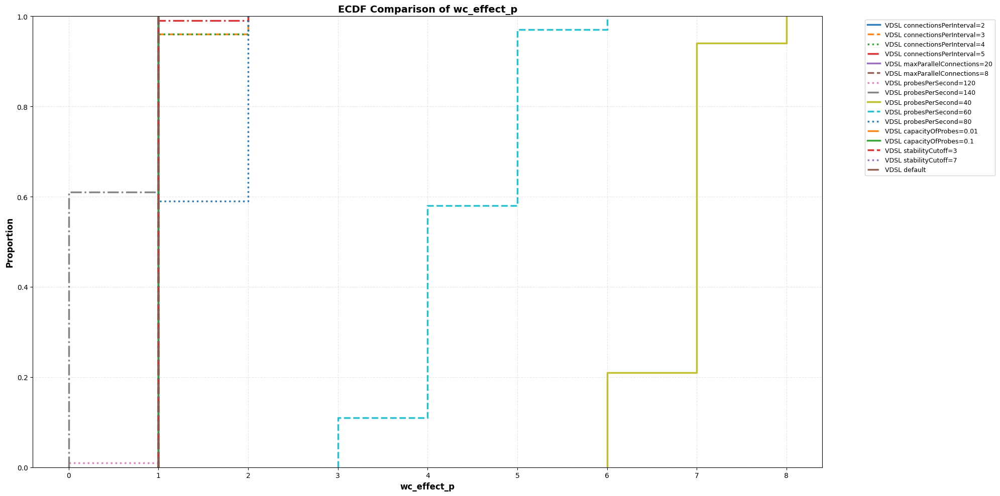

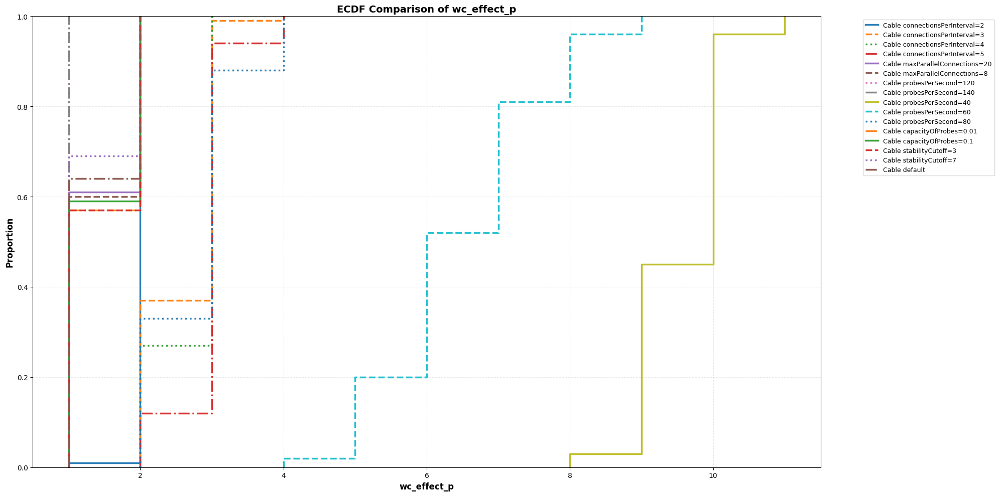

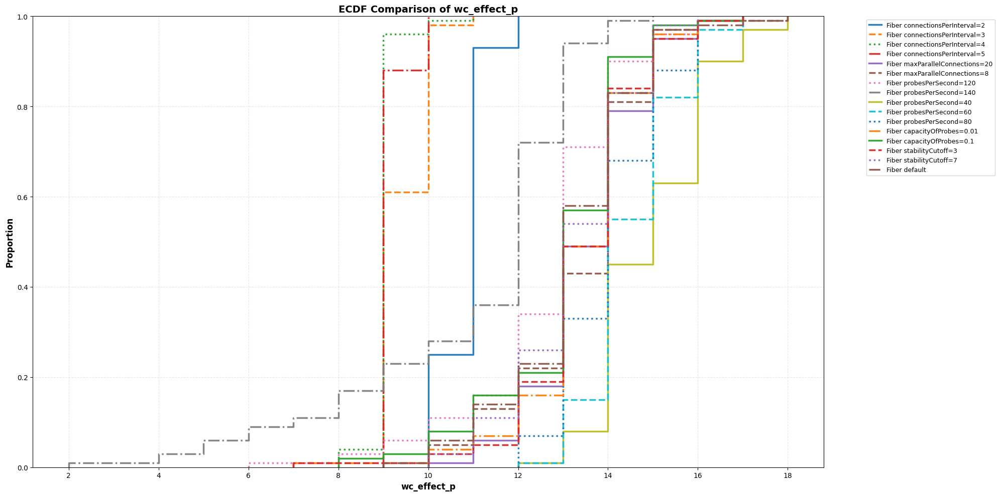

In [111]:
for env in environments:
    plot_ecdf_single(
    df_clean,
    'wc_effect_p',
    environments=[env],
    parameters=relevant_parameters+['default']
)

## working condition effect on rpm trimmed

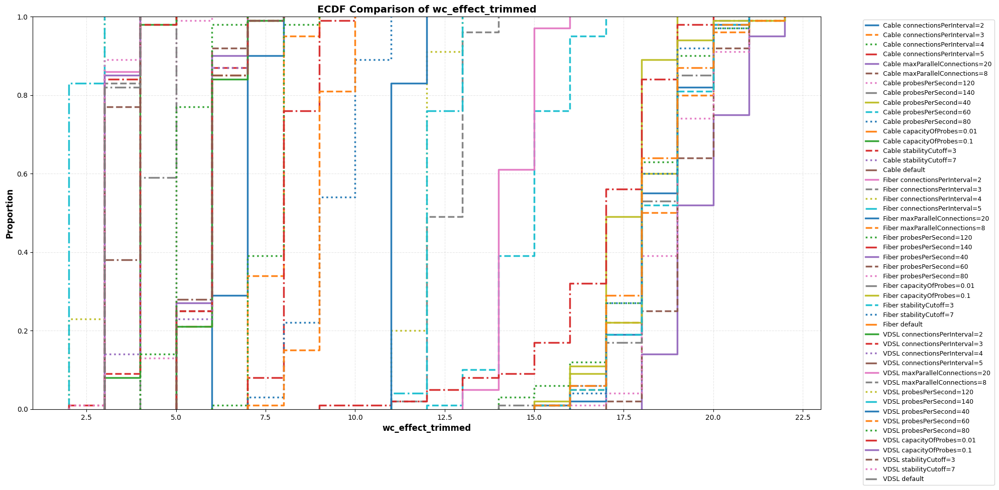

In [112]:
plot_ecdf_single(
    df_clean,
    'wc_effect_trimmed',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)

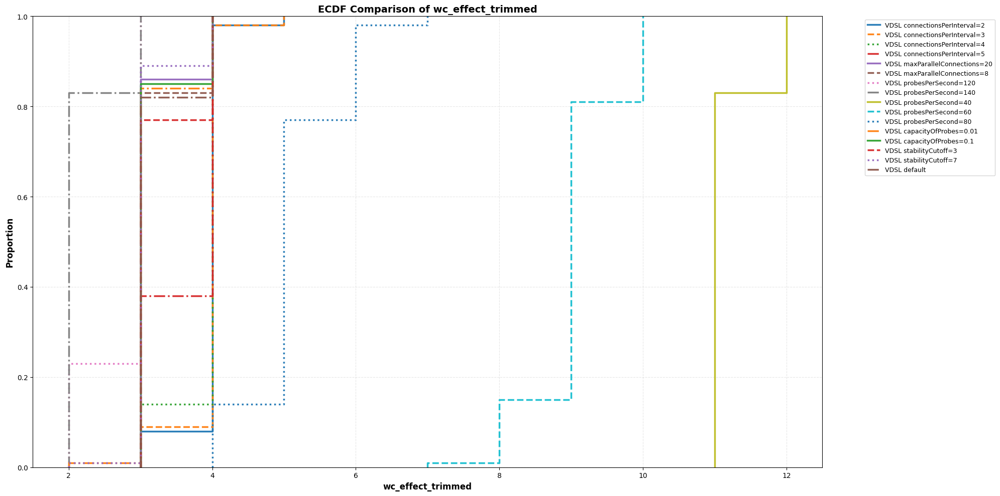

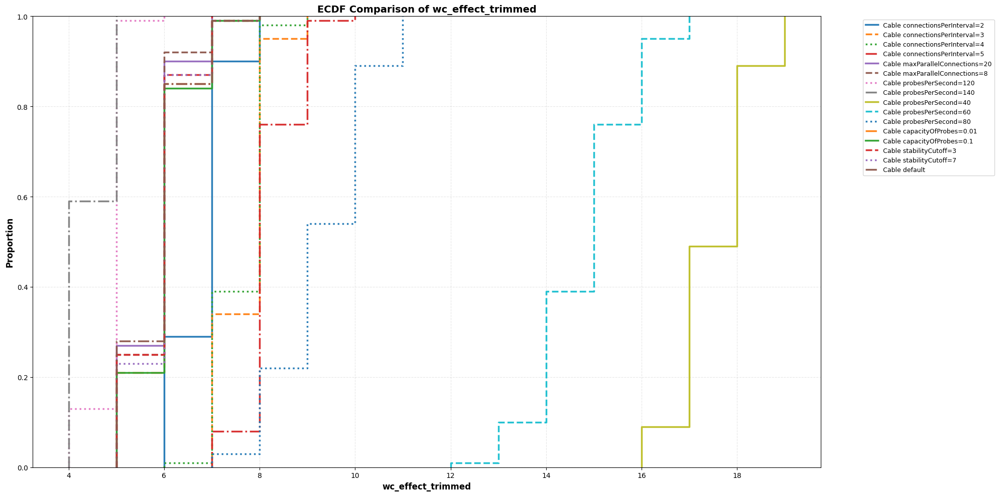

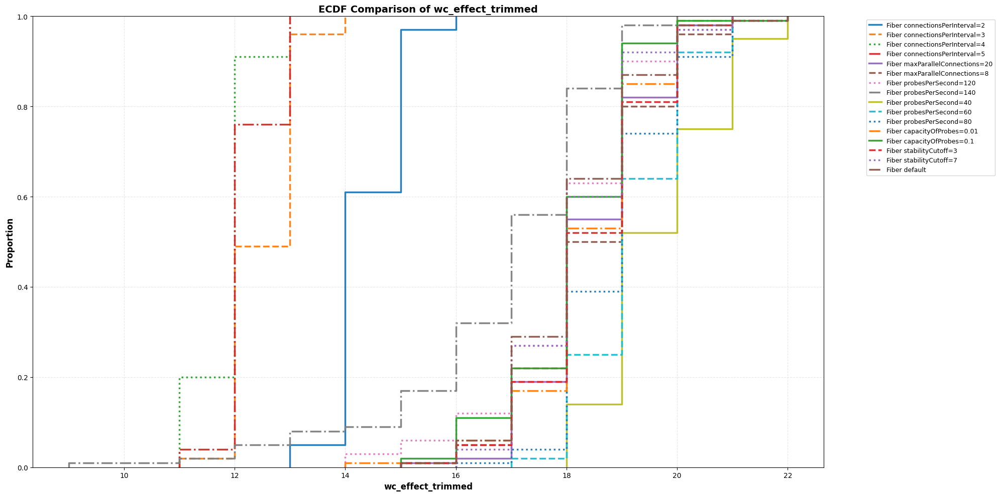

In [113]:
for env in environments:
    plot_ecdf_single(
    df_clean,
    'wc_effect_trimmed',
    environments=[env],
    parameters=relevant_parameters+['default']
)

## test duration

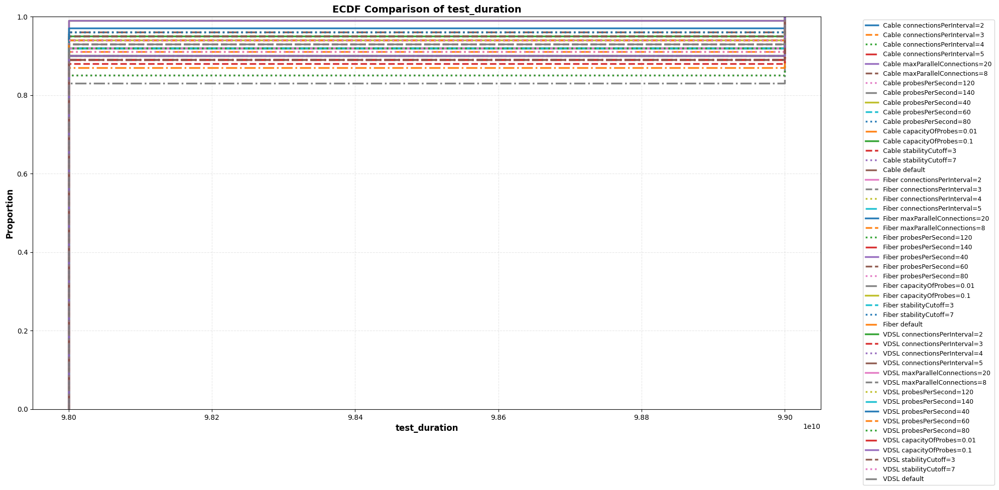

In [114]:
plot_ecdf_single(
    df_clean,
    'test_duration',
    environments=['Cable', 'Fiber', 'VDSL'],
    parameters=relevant_parameters+['default']
)